# TCC — versão organizada e reprodutível

Esta versão mantém os experimentos relevantes para o TCC: duas situações simuladas, TID-KMeans, DenStream, *grid search*, replicações, comparação online/offline e aplicação à Occupancy Detection.

**Ordem:** execute sequencialmente. Nas simulações, a padronização é sempre ajustada **somente às 300 observações iniciais** da respectiva situação; as colunas `Grupo` e `tempo` não entram no modelo. Os algoritmos são comparados sobre as mesmas variáveis transformadas.

**Importante:** os resultados numéricos antigos foram retirados das saídas do notebook, pois precisam ser recalculados com a padronização. Na parte da Occupancy, os arquivos `datatest.txt`, `datatraining.txt` e `datatest2.txt` devem estar no diretório de execução.

**Observação metodológica:** nas simulações, o DenStream é avaliado antes de atualizar cada lote, enquanto o TID-KMeans atualiza durante o lote. Esse protocolo foi mantido (não é uma correção de padronização).

**Nota:** a seleção em dados simulados usa ARI e, portanto, os rótulos apenas para escolher hiperparâmetros/avaliar. Na Occupancy a escolha continua baseada na silhueta de calibração; os rótulos de teste não são usados para selecionar parâmetros. A parte `offline` das simulações compara os resultados após atualizar o lote, diferentemente da avaliação principal pré-lote do DenStream.


**Revisão:** a calibração do DenStream importa `itertools` na própria célula e a função de seleção é definida antes de seu uso. Foi acrescentado gráfico de ARI por lote das execuções individuais após a seleção em grade.


## 0. Bibliotecas e funções de preparação

In [17]:
pip install river

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 11.9 MB/s  0:00:00


In [18]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from river import cluster as river_cluster

SEED_SIMULACAO = 42
COLUNAS_SIMULADAS = [f"Var{i}" for i in range(1, 11)]

def obter_variaveis(df):
    """Usar exclusivamente variáveis preditoras; excluir rótulo e tempo."""
    return df.drop(columns=["Grupo", "tempo"], errors="ignore")

def padronizar_situacao(base, lotes):
    """Ajusta no período inicial e transforma os lotes, sem vazamento futuro."""
    colunas = list(obter_variaveis(base).columns)
    assert colunas == COLUNAS_SIMULADAS, f"Colunas inesperadas: {colunas}"
    scaler = StandardScaler().fit(base[colunas].to_numpy(float))
    def aplicar(df):
        numericas = pd.DataFrame(
            scaler.transform(df[colunas].to_numpy(float)),
            index=df.index, columns=colunas
        )
        outras = df.drop(columns=colunas).copy()
        return pd.concat([numericas, outras], axis=1).loc[:, df.columns]
    return aplicar(base), [aplicar(lote) for lote in lotes], scaler


## 1. Geração das duas situações simuladas

Na nomenclatura do TCC, **Situação 1 = normais multivariadas** e **Situação 2 = variáveis de distribuições distintas**. Cada situação possui 300 observações iniciais e dez lotes posteriores.

In [3]:
def gerar_grupo(params, n):
    df = pd.DataFrame()

    for var, (dist, pars) in params.items():

        if dist == "normal":
            df[var] = np.random.normal(pars["loc"], pars["scale"], n)

        elif dist == "exponencial":
            df[var] = np.random.exponential(pars["scale"], n)

        elif dist == "poisson":
            df[var] = np.random.poisson(pars["lam"], n)

        elif dist == "bernoulli":
            df[var] = np.random.binomial(1, pars["p"], n)

        elif dist == "gamma":
            df[var] = np.random.gamma(pars["shape"], pars["scale"], n)

        elif dist == "uniforme":
            df[var] = np.random.uniform(pars["low"], pars["high"], n)

    return df

parametros = {
    0: {  # Grupo 0
        "Var1": ("normal", {"loc": 0, "scale": 1}),
        "Var2": ("exponencial", {"scale": 7}),
        "Var3": ("poisson", {"lam": 2}),
        "Var4": ("bernoulli", {"p": 0.2}),
        "Var5": ("gamma", {"shape": 2, "scale": 1}),
        "Var6": ("uniforme", {"low": 0, "high": 1}),
        "Var7": ("normal", {"loc": 1, "scale": 1}),
        "Var8": ("exponencial", {"scale": 3}),
        "Var9": ("poisson", {"lam": 3}),
        "Var10": ("uniforme", {"low": 1, "high": 2}),
    },

    1: {  # Grupo 1
        "Var1": ("normal", {"loc": 2, "scale": 1}),
        "Var2": ("exponencial", {"scale": 4}),
        "Var3": ("poisson", {"lam": 5}),
        "Var4": ("bernoulli", {"p": 0.5}),
        "Var5": ("gamma", {"shape": 5, "scale": 1}),
        "Var6": ("uniforme", {"low": 3, "high": 4}),
        "Var7": ("normal", {"loc": 3, "scale": 1}),
        "Var8": ("exponencial", {"scale": 2}),
        "Var9": ("poisson", {"lam": 6}),
        "Var10": ("uniforme", {"low": 4, "high": 5}),
    },

    2: {  # Grupo 2
        "Var1": ("normal", {"loc": 5, "scale": 1}),
        "Var2": ("exponencial", {"scale": 2}),
        "Var3": ("poisson", {"lam": 9}),
        "Var4": ("bernoulli", {"p": 0.8}),
        "Var5": ("gamma", {"shape": 9, "scale": 1}),
        "Var6": ("uniforme", {"low": 6, "high": 7}),
        "Var7": ("normal", {"loc": 6, "scale": 1}),
        "Var8": ("exponencial", {"scale": 1}),
        "Var9": ("poisson", {"lam": 10}),
        "Var10": ("uniforme", {"low": 7, "high": 8}),
    }
}

np.random.seed(42)

obs_por_grupo = 100
dados = []

for g in [0, 1, 2]:
    df_g = gerar_grupo(parametros[g], obs_por_grupo)
    df_g["Grupo"] = g
    dados.append(df_g)

df_final = pd.concat(dados, ignore_index=True)

# Tempo de chegada da base inicial
df_final["tempo"] = 0

print(df_final.shape)  # (300, 12)
print(df_final.head())

print(df_final.shape)  # (300, 11)
print(df_final.head())


(300, 12)
       Var1       Var2  Var3  Var4      Var5      Var6      Var7       Var8  \
0  0.496714   3.781913     3     0  4.819982  0.178036  2.029156   0.129014   
1 -0.138264   1.758171     2     0  1.365392  0.961070  1.472597   0.054107   
2  0.647689   0.893763     0     0  2.527303  0.148663  1.256030  13.199934   
3  1.523030   2.883360     1     1  2.101646  0.414624  1.982691   1.674659   
4 -0.234153  20.041848     4     1  1.506920  0.085350  2.665474   1.455116   

   Var9     Var10  Grupo  tempo  
0     4  1.736874      0      0  
1     2  1.862797      0      0  
2     4  1.216740      0      0  
3     2  1.095715      0      0  
4     2  1.023639      0      0  
(300, 12)
       Var1       Var2  Var3  Var4      Var5      Var6      Var7       Var8  \
0  0.496714   3.781913     3     0  4.819982  0.178036  2.029156   0.129014   
1 -0.138264   1.758171     2     0  1.365392  0.961070  1.472597   0.054107   
2  0.647689   0.893763     0     0  2.527303  0.148663  1.256030

In [4]:
np.random.seed(42)

n_grupos = 3
obs_por_grupo = 100
n_variaveis = 10

dados = []
grupos = []

# Médias
medias = [
    np.zeros(n_variaveis),
    np.ones(n_variaveis) * 5,
    np.ones(n_variaveis) * 10
]

# Covariâncias

# Grupos 0 e 1 (sem correlação)
cov_identidade = np.identity(n_variaveis)

# Grupo 2 (com correlação)
cov_correlacionada = np.full((n_variaveis, n_variaveis), 0.5)
np.fill_diagonal(cov_correlacionada, 1)

# Gerar dados
for g in range(n_grupos):

    if g == 2:
        cov = cov_correlacionada
    else:
        cov = cov_identidade

    cluster = np.random.multivariate_normal(
        mean=medias[g],
        cov=cov,
        size=obs_por_grupo
    )

    dados.append(cluster)
    grupos.extend([g] * obs_por_grupo)

# Juntar
dados = np.vstack(dados)

df_normais = pd.DataFrame(
    dados,
    columns=[f"Var{i+1}" for i in range(n_variaveis)]
)

df_normais["Grupo"] = grupos

# Adicionar coluna de tempo
df_normais["tempo"] = 0

print(df_normais.head())
print(df_normais.shape)


       Var1      Var2      Var3      Var4      Var5      Var6      Var7  \
0  0.496714 -0.138264  0.647689  1.523030 -0.234153 -0.234137  1.579213   
1 -0.463418 -0.465730  0.241962 -1.913280 -1.724918 -0.562288 -1.012831   
2  1.465649 -0.225776  0.067528 -1.424748 -0.544383  0.110923 -1.150994   
3 -0.601707  1.852278 -0.013497 -1.057711  0.822545 -1.220844  0.208864   
4  0.738467  0.171368 -0.115648 -0.301104 -1.478522 -0.719844 -0.460639   

       Var8      Var9     Var10  Grupo  tempo  
0  0.767435 -0.469474  0.542560      0      0  
1  0.314247 -0.908024 -1.412304      0      0  
2  0.375698 -0.600639 -0.291694      0      0  
3 -1.959670 -1.328186  0.196861      0      0  
4  1.057122  0.343618 -1.763040      0      0  
(300, 12)


In [5]:
# Dias de chegada de cada lote
tempos_lotes = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

parametros_stream = parametros.copy()

parametros_stream[3] = {
    "Var1": ("normal", {"loc": 8, "scale": 1}),
    "Var2": ("exponencial", {"scale": 1}),
    "Var3": ("poisson", {"lam": 12}),
    "Var4": ("bernoulli", {"p": 0.9}),
    "Var5": ("gamma", {"shape": 12, "scale": 1}),
    "Var6": ("uniforme", {"low": 8, "high": 9}),
    "Var7": ("normal", {"loc": 9, "scale": 1}),
    "Var8": ("exponencial", {"scale": 0.5}),
    "Var9": ("poisson", {"lam": 13}),
    "Var10": ("uniforme", {"low": 9, "high": 10}),
}

batches_stream = []

for t in range(10):

    dados_batch = []

    if t < 3:
        grupos_ativos = [0, 1, 2]
        n_por_grupo = [7, 7, 6]
    else:
        grupos_ativos = [0, 1, 2, 3]
        n_por_grupo = [5, 5, 5, 18]

    for g, n in zip(grupos_ativos, n_por_grupo):

        df_g = gerar_grupo(parametros_stream[g], n)

        df_g["Grupo"] = g

        dados_batch.append(df_g)

    batch = pd.concat(dados_batch, ignore_index=True)

    # Acrescenta o dia de chegada do lote
    batch["tempo"] = tempos_lotes[t]

    batches_stream.append(batch)


In [6]:
np.random.seed(42)

n_variaveis = 10
batches2 = []

# Tempos de chegada dos 10 lotes
tempos = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

for t in range(10):

    if t < 3:
        # antes do novo cluster
        dados = np.vstack([
            np.random.normal(0, 1, (15, n_variaveis)),
            np.random.normal(5, 1, (25, n_variaveis)),
            np.random.normal(10, 1, (10, n_variaveis))
        ])

        grupos = [0]*15 + [1]*25 + [2]*10

    else:
        # aparece novo cluster
        dados = np.vstack([
            np.random.normal(0, 1, (5, n_variaveis)),
            np.random.normal(5, 1, (10, n_variaveis)),
            np.random.normal(10, 1, (10, n_variaveis)),
            np.random.normal(15, 1, (25, n_variaveis))
        ])

        grupos = [0]*5 + [1]*10 + [2]*10 + [3]*25

    df = pd.DataFrame(
        dados,
        columns=[f"Var{i}" for i in range(1, n_variaveis+1)]
    )

    df["Grupo"] = grupos  # adiciona grupo

    # Adicionar coluna de tempo ao lote
    df["tempo"] = tempos[t]

    batches2.append(df)


In [7]:
# Guardar os dados ORIGINAIS: as funções de avaliação padronizam internamente
# com as 300 observações iniciais, inclusive dentro de cada replicação.
SITUACOES_BRUTAS = {
    "Situação 1": (df_normais.copy(deep=True), [b.copy(deep=True) for b in batches2]),
    "Situação 2": (df_final.copy(deep=True), [b.copy(deep=True) for b in batches_stream]),
}
SITUACOES_PADRONIZADAS = {}
for nome, (base, lotes) in SITUACOES_BRUTAS.items():
    base_pad, lotes_pad, scaler = padronizar_situacao(base, lotes)
    SITUACOES_PADRONIZADAS[nome] = (base_pad, lotes_pad, scaler)
    print(f"{nome}: inicial={len(base)}, lotes={len(lotes)}, total={len(base) + sum(map(len, lotes))}")
    print("  médias X0:", np.round(base_pad[COLUNAS_SIMULADAS].mean().to_numpy(), 7))
    print("  desvios X0 (ddof=0):", np.round(base_pad[COLUNAS_SIMULADAS].std(ddof=0).to_numpy(), 7))
    assert np.allclose(base_pad[COLUNAS_SIMULADAS].mean(), 0, atol=1e-12)
    assert np.allclose(base_pad[COLUNAS_SIMULADAS].std(ddof=0), 1, atol=1e-12)
    assert base_pad['Grupo'].equals(base['Grupo'])
    assert base_pad['tempo'].equals(base['tempo'])
    for bruto, pad in zip(lotes, lotes_pad):
        assert bruto['Grupo'].equals(pad['Grupo'])
        assert bruto['tempo'].equals(pad['tempo'])
        assert np.allclose(scaler.transform(bruto[COLUNAS_SIMULADAS].to_numpy(float)), pad[COLUNAS_SIMULADAS])


Situação 1: inicial=300, lotes=10, total=800
  médias X0: [ 0.  0.  0.  0. -0.  0.  0.  0.  0.  0.]
  desvios X0 (ddof=0): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Situação 2: inicial=300, lotes=10, total=591
  médias X0: [ 0. -0.  0.  0.  0.  0. -0. -0. -0. -0.]
  desvios X0 (ddof=0): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 2. Implementação do TID-KMeans e funções de avaliação

Uma única classe para as simulações. O protocolo de preparação para ambos os algoritmos é implementado nas funções abaixo. Nas simulações, **sempre forneça as bases brutas** às funções `avaliar_ttid` e `avaliar_denstream_sim`, que ajustam seus próprios scalers apenas na base inicial.

In [8]:
import numpy as np
from sklearn.cluster import KMeans


class TIDKMeans:

    def __init__(
        self,
        n_clusters,
        lambda_decay,
        fator_limiar
    ):

        self.n_clusters = n_clusters
        self.lambda_decay = lambda_decay
        self.fator_limiar = fator_limiar

        # Tempo do último lote processado
        self.ultimo_tempo = 0

    # ==================================================
    # FASE INICIAL: K-MEANS
    # ==================================================

    def fit_initial(self, X0):

        kmeans = KMeans(
            n_clusters=self.n_clusters,
            random_state=123,
            n_init=50
        )

        labels = kmeans.fit_predict(X0)

        self.labels_initial = labels
        self.clusters = []


        # Informações iniciais de cada cluster
        for j in range(self.n_clusters):

            pontos_cluster = X0[labels == j]

            N_j = len(pontos_cluster)

            LS_j = pontos_cluster.sum(axis=0)

            c_j = LS_j / N_j

            # Distâncias ao centróide
            distancias = np.linalg.norm(
                pontos_cluster - c_j,
                axis=1
            )

            # Limiar específico do cluster
            # Utiliza o fator definido na inicialização
            D_j = self.fator_limiar * distancias.max()

            self.clusters.append({
                "LS": LS_j,
                "N": N_j,
                "centroide": c_j,
                "limiar": D_j
            })

        # Média dos limiares iniciais
        self.limiar_medio = np.mean([
            c["limiar"] for c in self.clusters
        ])

        # A base inicial corresponde ao tempo 0
        self.ultimo_tempo = 0

    # ==================================================
    # DECAIMENTO TEMPORAL DE TODOS OS CLUSTERS
    # ==================================================

    def aplicar_decaimento(self, tempo_atual):

        # Diferença em dias desde o último lote
        delta_t = tempo_atual - self.ultimo_tempo

        if delta_t < 0:
            raise ValueError(
                "O tempo atual não pode ser menor "
                "que o tempo do último lote processado."
            )

        # Fator de decaimento
        peso = 2.0 ** (
             -self.lambda_decay * delta_t
            )

        # Aplicar decaimento em TODOS os clusters
        for cluster in self.clusters:

            cluster["LS"] *= peso
            cluster["N"] *= peso

            # Atualizar centróide
            cluster["centroide"] = (
                cluster["LS"] / cluster["N"]
            )

        # Atualiza o tempo global do fluxo
        self.ultimo_tempo = tempo_atual

    # ==================================================
    # PROCESSAR UM LOTE
    # ==================================================

    def process_batch(self, X_batch, tempo):

        # 1. Aplicar decaimento em todos os clusters
        self.aplicar_decaimento(tempo)

        labels_pred = []

        # 2. Inserir as observações do lote
        for x_t in X_batch:

            label = self.process_one(x_t)

            labels_pred.append(label)

        return np.array(labels_pred)

    # ==================================================
    # PROCESSAR UMA OBSERVAÇÃO
    # ==================================================

    def process_one(self, x_t):

        # Calcular distância aos centróides atuais
        distancias = []

        for idx, cluster in enumerate(self.clusters):

            d = np.linalg.norm(
                x_t - cluster["centroide"]
            )

            distancias.append((idx, d))

        # Ordenar pela menor distância
        distancias.sort(key=lambda x: x[1])

        # Tentar inserir no cluster mais próximo
        for idx, d in distancias:

            cluster = self.clusters[idx]

            if d <= cluster["limiar"]:

                # Acrescentar a observação
                cluster["LS"] += x_t
                cluster["N"] += 1

                # Atualizar centróide
                cluster["centroide"] = (
                    cluster["LS"] / cluster["N"]
                )

                return idx

        # Nenhum cluster aceitou a observação:
        # criar um novo cluster
        novo_cluster = {
            "LS": x_t.copy(),
            "N": 1.0,
            "centroide": x_t.copy(),
            "limiar": self.limiar_medio
        }

        self.clusters.append(novo_cluster)

        return len(self.clusters) - 1

    # ==================================================
    # FUNÇÕES AUXILIARES
    # ==================================================

    def get_centroids(self):

        return np.array([
            c["centroide"] for c in self.clusters
        ])

    def get_number_clusters(self):

        return len(self.clusters)

    def get_cluster_info(self):

        return self.clusters


In [9]:
from sklearn.preprocessing import StandardScaler

import numpy as np
import pandas as pd

from sklearn.metrics import adjusted_rand_score
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment
from river import cluster as river_cluster

# ==========================================================
# FUNÇÕES AUXILIARES
# ==========================================================

def obter_variaveis(df):
    """Retorna somente as variáveis usadas na clusterização."""
    colunas_excluir = ["Grupo", "tempo"]
    return df.drop(columns=colunas_excluir, errors="ignore")


def obter_centros_denstream(modelo, colunas):
    """
    Obtém os centros dos p-micro-clusters do DenStream,
    na mesma ordem das colunas usadas como atributos.
    """
    centros = []

    for mc in modelo.p_micro_clusters.values():
        centro = mc.calc_center(modelo.timestamp)

        vetor = np.array(
            [centro.get(coluna, 0.0) for coluna in colunas],
            dtype=float
        )

        centros.append(vetor)

    if len(centros) == 0:
        return np.empty((0, len(colunas)))

    return np.vstack(centros)


def alinhar_rotulos_denstream(
    centros_atuais,
    centros_anteriores,
    ids_anteriores,
    proximo_id,
    distancia_maxima
):
    """
    Tenta manter IDs de clusters consistentes entre lotes,
    associando centros atuais aos centros anteriores por
    distância mínima.

    Centros sem correspondência recebem novos IDs.
    """
    n_atual = len(centros_atuais)
    ids_atuais = np.full(n_atual, -1, dtype=int)

    if n_atual == 0:
        return ids_atuais, proximo_id

    if len(centros_anteriores) > 0:
        distancias = cdist(centros_atuais, centros_anteriores)

        linhas, colunas = linear_sum_assignment(distancias)

        for i_atual, i_anterior in zip(linhas, colunas):
            if distancias[i_atual, i_anterior] <= distancia_maxima:
                ids_atuais[i_atual] = ids_anteriores[i_anterior]

    for i in range(n_atual):
        if ids_atuais[i] == -1:
            ids_atuais[i] = proximo_id
            proximo_id += 1

    return ids_atuais, proximo_id


def predizer_por_centros(X, centros):
    """Associa cada observação ao centro mais próximo."""
    if len(centros) == 0:
        raise ValueError(
            "O DenStream não possui p-micro-clusters "
            "disponíveis para realizar a predição."
        )

    distancias = cdist(X, centros)
    return distancias.argmin(axis=1)


# ==========================================================
# AVALIAÇÃO DO DYNAMIC K-MEANS
# ==========================================================

def avaliar_tid_sim(
    df_base, lotes, lambda_decay, fator_limiar, n_clusters=2
):
    # Padronização ajustada exclusivamente à base inicial desta replicação
    X0_df = obter_variaveis(df_base)
    scaler = StandardScaler().fit(X0_df.to_numpy(dtype=float))
    X0 = scaler.transform(X0_df.to_numpy(dtype=float))
    y0 = df_base["Grupo"].to_numpy()

    modelo = TIDKMeans(
        n_clusters,
        lambda_decay=lambda_decay,
        fator_limiar=fator_limiar
    )

    modelo.fit_initial(X0)

    # Avaliação da base inicial
    pred_inicial = modelo.labels_initial
    ari_inicial = adjusted_rand_score(y0, pred_inicial)

    # Armazenamento dos resultados
    resultados_lotes = []
    y_true_stream = []
    y_pred_stream = []

    y_true_global = list(y0)
    y_pred_global = list(pred_inicial)

    # Processamento dos lotes
    for i, lote in enumerate(lotes, start=1):
        X_lote = scaler.transform(obter_variaveis(lote).to_numpy(dtype=float))
        y_lote = lote["Grupo"].to_numpy()

        tempo_lote = (
            lote["tempo"].iloc[0]
            if "tempo" in lote.columns
            else i
        )

        pred = modelo.process_batch(X_lote, tempo_lote)

        ari_lote = adjusted_rand_score(y_lote, pred)

        resultados_lotes.append({
            "Lote": i,
            "Tempo": tempo_lote,
            "ARI": ari_lote,
            "Numero_clusters": modelo.get_number_clusters()
        })

        y_true_stream.extend(y_lote)
        y_pred_stream.extend(pred)

        y_true_global.extend(y_lote)
        y_pred_global.extend(pred)

    # ARI considerando somente as observações do fluxo
    ari_stream = adjusted_rand_score(
        y_true_stream, y_pred_stream
    )

    # ARI incluindo a base inicial e todo o fluxo
    ari_global = adjusted_rand_score(
        y_true_global, y_pred_global
    )

    return {
        "ARI_inicial": ari_inicial,
        "ARI_stream": ari_stream,
        "ARI_global_com_base": ari_global,
        "ARI_lotes": resultados_lotes,
        "Numero_clusters_final": modelo.get_number_clusters(),
        "y_inicial": y0, "pred_inicial": np.asarray(pred_inicial),
        "y_stream": np.asarray(y_true_stream),
        "pred_stream": np.asarray(y_pred_stream),
    }



# ==========================================================
# AVALIAÇÃO DO DENSTREAM
# ==========================================================

def avaliar_denstream_sim(df_base, lotes, config):

    # ------------------------------------------------------
    # 1. Inicializar e treinar com a base inicial
    # ------------------------------------------------------

    X0_df = obter_variaveis(df_base)
    colunas = list(X0_df.columns)

    # O mesmo protocolo aplicado ao TID-KMeans
    scaler = StandardScaler().fit(X0_df.to_numpy(dtype=float))
    X0 = scaler.transform(X0_df.to_numpy(dtype=float))
    y0 = df_base["Grupo"].to_numpy()

    modelo = river_cluster.DenStream(
        epsilon=config["epsilon"],
        beta=config["beta"],
        mu=config["mu"],
        decaying_factor=config["decaying_factor"],
        n_samples_init=config["n_samples_init"],
        stream_speed=config["stream_speed"]
    )

    # O River recebe cada observação como um dicionário
    X0_pad_df = pd.DataFrame(X0, columns=colunas)
    for registro in X0_pad_df.to_dict(orient="records"):
        modelo.learn_one(registro)

    # Centros disponíveis após o treinamento inicial
    centros = obter_centros_denstream(modelo, colunas)

    if len(centros) == 0:
        raise ValueError(
            "O DenStream não formou p-micro-clusters "
            "após o treinamento inicial."
        )

    # IDs iniciais dos clusters
    ids_centros = np.arange(len(centros), dtype=int)
    proximo_id = len(centros)

    # Avaliação retrospectiva da base inicial
    pred_inicial = predizer_por_centros(X0, centros)
    ari_inicial = adjusted_rand_score(y0, pred_inicial)

    y_true_global = list(y0)
    y_pred_global = list(ids_centros[pred_inicial])

    y_true_stream = []
    y_pred_stream = []
    resultados_lotes = []

    # ------------------------------------------------------
    # 2. Processar o fluxo lote a lote
    # ------------------------------------------------------

    for i, lote in enumerate(lotes, start=1):

        X_lote_df = obter_variaveis(lote)
        X_lote = scaler.transform(X_lote_df.to_numpy(dtype=float))
        y_lote = lote["Grupo"].to_numpy()

        tempo_lote = (
            lote["tempo"].iloc[0]
            if "tempo" in lote.columns
            else i
        )

        # Predizer usando os centros disponíveis ANTES
        # de aprender as observações deste lote
        pred_indices = predizer_por_centros(X_lote, centros)
        pred = ids_centros[pred_indices]

        ari_lote = adjusted_rand_score(y_lote, pred)

        y_true_stream.extend(y_lote)
        y_pred_stream.extend(pred)

        y_true_global.extend(y_lote)
        y_pred_global.extend(pred)

        # Aprender as observações do lote, uma a uma
        X_lote_pad_df = pd.DataFrame(X_lote, columns=colunas)
        for registro in X_lote_pad_df.to_dict(orient="records"):
            modelo.learn_one(registro)

        # Obter os centros atualizados para o próximo lote
        centros_novos = obter_centros_denstream(modelo, colunas)

        if len(centros_novos) > 0:

            ids_novos, proximo_id = alinhar_rotulos_denstream(
                centros_atuais=centros_novos,
                centros_anteriores=centros,
                ids_anteriores=ids_centros,
                proximo_id=proximo_id,
                distancia_maxima=config["epsilon"]
            )

            centros = centros_novos
            ids_centros = ids_novos

        # Quantidade de p-micro-clusters após aprender o lote
        resultados_lotes.append({
            "Lote": i,
            "Tempo": tempo_lote,
            "ARI": ari_lote,
            "Numero_clusters": len(modelo.p_micro_clusters)
        })

    # ------------------------------------------------------
    # 3. Calcular os resultados gerais
    # ------------------------------------------------------

    ari_stream = adjusted_rand_score(
        y_true_stream,
        y_pred_stream
    )

    ari_global = adjusted_rand_score(
        y_true_global,
        y_pred_global
    )

    return {
        "ARI_inicial": ari_inicial,
        "ARI_stream": ari_stream,
        "ARI_global_com_base": ari_global,
        "ARI_lotes": resultados_lotes,
        "Numero_clusters_final": len(modelo.p_micro_clusters),
        "y_inicial": y0, "pred_inicial": np.asarray(pred_inicial),
        "y_stream": np.asarray(y_true_stream),
        "pred_stream": np.asarray(y_pred_stream),
    }


## 3. Busca em grade — TID-KMeans e DenStream

A grade do decaimento foi **preservada exatamente como você pediu**: `[0.01, 0.1, 0.5, 1]` para ambos. TID-KMeans: 204 combinações por situação; DenStream: 144 por situação. A seleção utiliza ARI global e os mesmos dados brutos são fornecidos a ambos os procedimentos, cada qual padronizando apenas pelo período inicial.

In [10]:
LAMBDA_GRID = [0.01, 0.1, 0.5, 1]
ALPHA_GRID = np.round(np.arange(1.00, 1.501, 0.01), 2)
EPSILON_GRID = [2, 5, 8, 11]
MU_GRID = [2, 5, 8]
BETA_GRID = [0.1, 0.2, 0.5]
DECAY_GRID = [0.01, 0.1, 0.5, 1]

print('TID-KMeans:', len(LAMBDA_GRID)*len(ALPHA_GRID), 'combinações por situação')
print('DenStream:', len(EPSILON_GRID)*len(MU_GRID)*len(BETA_GRID)*len(DECAY_GRID), 'combinações por situação')

def grid_tid_situacoes(situacoes):
    linhas = []
    for nome, (base, lotes) in situacoes.items():
        for lam, alpha in itertools.product(LAMBDA_GRID, ALPHA_GRID):
            r = avaliar_tid_sim(base, lotes, float(lam), float(alpha), n_clusters=3)
            linhas.append({
                'Situação': nome, 'lambda_decay': float(lam), 'fator_limiar': float(alpha),
                'ARI_global': r['ARI_global_com_base'], 'ARI_stream': r['ARI_stream'],
                'Clusters_finais': r['Numero_clusters_final']
            })
    return pd.DataFrame(linhas).sort_values(['Situação','ARI_global'], ascending=[True, False]).reset_index(drop=True)

def grid_denstream_situacoes(situacoes):
    linhas = []
    for nome, (base, lotes) in situacoes.items():
        for eps, mu, beta, d in itertools.product(EPSILON_GRID, MU_GRID, BETA_GRID, DECAY_GRID):
            config = dict(epsilon=eps, mu=mu, beta=beta, decaying_factor=d, n_samples_init=300, stream_speed=1)
            try:
                r = avaliar_denstream_sim(base, lotes, config)
                linhas.append({
                    'Situação':nome, **config, 'ARI_global':r['ARI_global_com_base'],
                    'ARI_stream':r['ARI_stream'], 'Clusters_finais':r['Numero_clusters_final'], 'Erro':''
                })
            except (ValueError, OverflowError, ZeroDivisionError) as exc:
                linhas.append({
                    'Situação':nome, **config, 'ARI_global':np.nan,
                    'ARI_stream':np.nan, 'Clusters_finais':np.nan, 'Erro':str(exc)
                })
    return pd.DataFrame(linhas).sort_values(['Situação','ARI_global'], ascending=[True, False]).reset_index(drop=True)


TID-KMeans: 204 combinações por situação
DenStream: 144 combinações por situação


In [11]:
grid_tid = grid_tid_situacoes(SITUACOES_BRUTAS)
print(grid_tid.groupby('Situação').head(5).round(4).to_string(index=False))
grid_tid.to_csv('grid_tid_padronizado.csv',index=False)


  Situação  lambda_decay  fator_limiar  ARI_global  ARI_stream  Clusters_finais
Situação 1          0.01          1.10      1.0000      1.0000                4
Situação 1          0.01          1.11      1.0000      1.0000                4
Situação 1          0.01          1.12      1.0000      1.0000                4
Situação 1          0.01          1.13      1.0000      1.0000                4
Situação 1          0.01          1.14      1.0000      1.0000                4
Situação 2          0.01          1.00      0.9953      0.9938                4
Situação 2          0.01          1.01      0.9953      0.9938                4
Situação 2          0.10          1.00      0.9953      0.9938                4
Situação 2          0.10          1.01      0.9953      0.9938                4
Situação 2          0.10          1.02      0.9953      0.9938                4


In [12]:
grid_denstream = grid_denstream_situacoes(SITUACOES_BRUTAS)
print(grid_denstream.groupby('Situação').head(5).round(4).to_string(index=False))
grid_denstream.to_csv('grid_denstream_padronizado.csv',index=False)


  Situação  epsilon  mu  beta  decaying_factor  n_samples_init  stream_speed  ARI_global  ARI_stream  Clusters_finais Erro
Situação 1        2   5   0.5             0.01             300             1      0.7469      0.6945              3.0     
Situação 1        2   5   0.5             0.10             300             1      0.7469      0.6945              3.0     
Situação 1        2   8   0.2             0.01             300             1      0.7469      0.6945              3.0     
Situação 1        2   8   0.2             0.10             300             1      0.7469      0.6945              3.0     
Situação 1        2   8   0.5             0.01             300             1      0.7469      0.6945              3.0     
Situação 2        5   5   0.5             0.01             300             1      0.5403      0.7396              3.0     
Situação 2        5   5   0.5             0.10             300             1      0.5403      0.7396              3.0     
Situação 2      

In [72]:
for metodo, tabela in [
    ("TID-KMeans", grid_tid),
    ("DenStream", grid_denstream)
]:
    resumo = (
        tabela.groupby("Situação")["ARI_global"]
        .agg(["min", "max"])
    )
    resumo["amplitude"] = resumo["max"] - resumo["min"]

    print(f"\n{metodo}")
    print(resumo.round(4))



TID-KMeans
               min     max  amplitude
Situação                             
Situação 1  0.9484  1.0000     0.0516
Situação 2  0.7205  0.9953     0.2748

DenStream
            min     max  amplitude
Situação                          
Situação 1  0.0  0.7469     0.7469
Situação 2  0.0  0.5403     0.5403


## 4. Execuções individuais com os parâmetros selecionados

As configurações são extraídas dos próprios grids, **sem manter valores antigos escritos à mão**. Assim, matrizes, ARIs e replicações usam a mesma escolha de hiperparâmetros.

In [13]:
def melhores_configs(grid_tid, grid_denstream):
    escolhas = {}
    for nome in SITUACOES_BRUTAS:
        t = grid_tid[(grid_tid['Situação']==nome) & grid_tid['ARI_global'].notna()].iloc[0]
        d = grid_denstream[(grid_denstream['Situação']==nome) & grid_denstream['ARI_global'].notna()].iloc[0]
        escolhas[nome] = {
            'TID': dict(lambda_decay=float(t['lambda_decay']), fator_limiar=float(t['fator_limiar'])),
            'DenStream': dict(
                epsilon=float(d['epsilon']), mu=int(d['mu']), beta=float(d['beta']),
                decaying_factor=float(d['decaying_factor']), n_samples_init=300, stream_speed=1
            )
        }
    return escolhas

ESCOLHAS_SIM = melhores_configs(grid_tid, grid_denstream)
for nome, escolhas in ESCOLHAS_SIM.items():
    print(nome, escolhas)

RESULTADOS_INDIVIDUAIS = {}
for nome, (base, lotes) in SITUACOES_BRUTAS.items():
    config = ESCOLHAS_SIM[nome]
    resultado_tid = avaliar_tid_sim(base, lotes, **config['TID'], n_clusters=3)
    resultado_den = avaliar_denstream_sim(base, lotes, config['DenStream'])
    RESULTADOS_INDIVIDUAIS[nome] = {'TID-KMeans': resultado_tid, 'DenStream': resultado_den}
    for metodo, resultado in RESULTADOS_INDIVIDUAIS[nome].items():
        print(f"\n{nome} — {metodo}: inicial={resultado['ARI_inicial']:.4f}, fluxo={resultado['ARI_stream']:.4f}, global={resultado['ARI_global_com_base']:.4f}")
        print(pd.DataFrame(resultado['ARI_lotes']).round(4).to_string(index=False))
        print('Matriz inicial:')
        print(pd.crosstab(resultado['y_inicial'], resultado['pred_inicial']))
        ultimo = lotes[-1]
        n_ultimo = len(ultimo)
        print('Matriz do último lote:')
        print(pd.crosstab(resultado['y_stream'][-n_ultimo:], resultado['pred_stream'][-n_ultimo:]))


Situação 1 {'TID': {'lambda_decay': 0.01, 'fator_limiar': 1.1}, 'DenStream': {'epsilon': 2.0, 'mu': 5, 'beta': 0.5, 'decaying_factor': 0.01, 'n_samples_init': 300, 'stream_speed': 1}}
Situação 2 {'TID': {'lambda_decay': 0.01, 'fator_limiar': 1.0}, 'DenStream': {'epsilon': 5.0, 'mu': 5, 'beta': 0.5, 'decaying_factor': 0.01, 'n_samples_init': 300, 'stream_speed': 1}}

Situação 1 — TID-KMeans: inicial=1.0000, fluxo=1.0000, global=1.0000
 Lote  Tempo  ARI  Numero_clusters
    1      1  1.0                3
    2      2  1.0                3
    3      3  1.0                3
    4      4  1.0                4
    5      5  1.0                4
    6      6  1.0                4
    7      7  1.0                4
    8      8  1.0                4
    9      9  1.0                4
   10     10  1.0                4
Matriz inicial:
col_0    0    1    2
row_0               
0        0  100    0
1        0    0  100
2      100    0    0
Matriz do último lote:
col_0   0  1   2   3
row_0       

### ARI por lote — comparação individual nas situações simuladas

Os gráficos utilizam as execuções individuais com os parâmetros escolhidos pela busca em grade. São mostrados os ARIs de cada lote, sem incluir o ARI global ou o conjunto inicial. Os dados das duas situações foram padronizados usando apenas a base inicial.

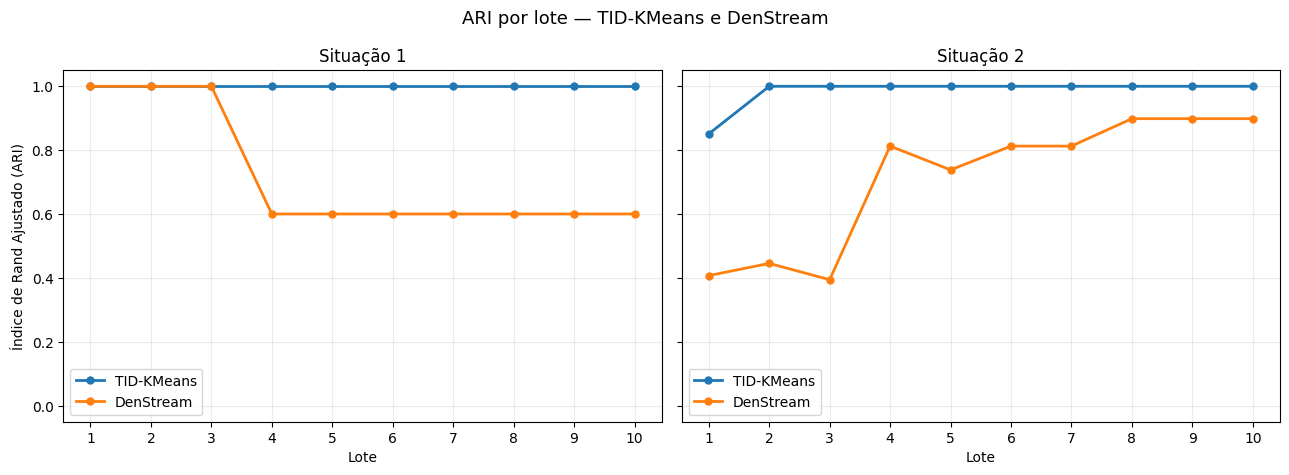

In [14]:
# Gráficos das execuções individuais (não representam médias das replicações)
import matplotlib.pyplot as plt
import pandas as pd

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)

for ax, nome in zip(axes, ["Situação 1", "Situação 2"]):
    resultados = RESULTADOS_INDIVIDUAIS[nome]
    for metodo, resultado in resultados.items():
        tabela = pd.DataFrame(resultado["ARI_lotes"]).sort_values("Lote")
        ax.plot(tabela["Lote"], tabela["ARI"], marker="o",
                linewidth=2, markersize=5, label=metodo)
    ax.set_title(nome)
    ax.set_xlabel("Lote")
    ax.set_xticks(range(1, 11))
    ax.set_ylim(-0.05, 1.05)
    ax.grid(alpha=0.25)
    ax.legend()

axes[0].set_ylabel("Índice de Rand Ajustado (ARI)")
fig.suptitle("ARI por lote — TID-KMeans e DenStream", fontsize=13)
fig.tight_layout()
plt.show()

# Opcional: salvar a figura para inclusão no TCC
fig.savefig("ari_por_lote_situacoes_simuladas.png", dpi=300, bbox_inches="tight")


## 5. DenStream: verificação adicional da etapa offline

Esta comparação usa **a mesma padronização** e as configurações selecionadas. Aqui ambos os ARIs por lote são calculados **depois da atualização do lote**. Portanto, esta é uma verificação interna online/offline, não substitui os ARIs pré-lote da comparação principal.

In [15]:
import numpy as np
import pandas as pd

from river import cluster
from scipy.spatial.distance import cdist
from sklearn.metrics import adjusted_rand_score


def comparar_denstream_online_offline(df_base, lotes, config):
    """
    Compara:
    - Online: centro do p-micro-cluster mais próximo.
    - Offline: macrocluster produzido pelo DenStream do River.

    A avaliação ocorre após a atualização de cada lote.
    """

    # As entradas desta função precisam estar padronizadas com o scaler da base inicial.
    modelo = cluster.DenStream(**config)

    colunas = df_base.drop(columns=["Grupo", "tempo"], errors="ignore").columns.tolist()
    resultados = []

    def avaliar_etapa(df, etapa):
        X = df[colunas].to_numpy(dtype=float)
        y = df["Grupo"].to_numpy()

        # ---------------------------
        # ONLINE: p-micro-clusters
        # ---------------------------
        centros_micro = []

        for mc in modelo.p_micro_clusters.values():
            centro = mc.calc_center(modelo.timestamp)
            centros_micro.append([
                centro.get(c, 0.0) for c in colunas
            ])

        if centros_micro:
            centros_micro = np.asarray(centros_micro)
            pred_online = cdist(
                X, centros_micro
            ).argmin(axis=1)
        else:
            pred_online = np.full(len(X), -1)

        # ---------------------------
        # OFFLINE: macroclusters
        # ---------------------------
        # predict_one executa a etapa offline
        # a partir do estado atual do modelo.
        if len(X):
            modelo.predict_one(
                dict(zip(colunas, X[0]))
            )

        centros_macro_dict = modelo.centers
        centros_macro = np.asarray([
            [centro.get(c, 0.0) for c in colunas]
            for centro in centros_macro_dict.values()
        ]).reshape(-1, len(colunas))

        if len(centros_macro):
            pred_offline = cdist(
                X, centros_macro
            ).argmin(axis=1)
        else:
            pred_offline = np.full(len(X), -1)

        ari_online = adjusted_rand_score(y, pred_online)
        ari_offline = adjusted_rand_score(y, pred_offline)

        resultados.append({
            "Etapa": etapa,
            "N_micro": len(centros_micro),
            "N_macro": len(centros_macro),
            "ARI_online": ari_online,
            "ARI_offline": ari_offline,
            "Diferenca": ari_offline - ari_online
        })

    # Inicialização
    for x in df_base[colunas].to_dict(orient="records"):
        modelo.learn_one(x)

    avaliar_etapa(df_base, "Inicial")

    # Fluxo: atualiza antes de avaliar cada lote
    for t, lote in enumerate(lotes, start=1):
        for x in lote[colunas].to_dict(orient="records"):
            modelo.learn_one(x)

        avaliar_etapa(lote, f"Lote {t}")

    return pd.DataFrame(resultados)


In [16]:
RESULTADOS_OFFLINE_SIM = {}
for nome, (base_pad, lotes_pad, _) in SITUACOES_PADRONIZADAS.items():
    tab = comparar_denstream_online_offline(base_pad, lotes_pad, ESCOLHAS_SIM[nome]['DenStream'])
    RESULTADOS_OFFLINE_SIM[nome] = tab
    print(f"\n{nome} — comparação pós-atualização (online/offline):")
    print(tab.round(4).to_string(index=False))
    print('Maior diferença absoluta de ARI:', tab['Diferenca'].abs().max())



Situação 1 — comparação pós-atualização (online/offline):
  Etapa  N_micro  N_macro  ARI_online  ARI_offline  Diferenca
Inicial        3        3      1.0000       1.0000        0.0
 Lote 1        3        3      1.0000       1.0000        0.0
 Lote 2        3        3      1.0000       1.0000        0.0
 Lote 3        3        3      1.0000       1.0000        0.0
 Lote 4        3        3      0.6003       0.6003        0.0
 Lote 5        3        3      0.6003       0.6003        0.0
 Lote 6        3        3      0.6003       0.6003        0.0
 Lote 7        3        3      0.6003       0.6003        0.0
 Lote 8        3        3      0.6003       0.6003        0.0
 Lote 9        3        3      0.6003       0.6003        0.0
Lote 10        3        3      0.6003       0.6003        0.0
Maior diferença absoluta de ARI: 0.0

Situação 2 — comparação pós-atualização (online/offline):
  Etapa  N_micro  N_macro  ARI_online  ARI_offline  Diferenca
Inicial        3        3      0.4473  

## 6. Replicações independentes (30 sementes)

Cada repetição gera uma nova base e reajusta o `StandardScaler` **apenas na base inicial daquela repetição**. A configuração de hiperparâmetros vem da busca em grade anterior (não é reajustada a cada repetição).

In [17]:
import numpy as np
import pandas as pd


def gerar_grupo(params, n):
    df = pd.DataFrame()

    for var, (dist, pars) in params.items():

        if dist == "normal":
            df[var] = np.random.normal(
                pars["loc"], pars["scale"], n
            )

        elif dist == "exponencial":
            df[var] = np.random.exponential(
                pars["scale"], n
            )

        elif dist == "poisson":
            df[var] = np.random.poisson(
                pars["lam"], n
            )

        elif dist == "bernoulli":
            df[var] = np.random.binomial(
                1, pars["p"], n
            )

        elif dist == "gamma":
            df[var] = np.random.gamma(
                pars["shape"], pars["scale"], n
            )

        elif dist == "uniforme":
            df[var] = np.random.uniform(
                pars["low"], pars["high"], n
            )

    return df


def gerar_base_1(seed):

    # Reproduzibilidade da replicação
    np.random.seed(seed)

    parametros = {
        0: {
            "Var1": ("normal", {"loc": 0, "scale": 1}),
            "Var2": ("exponencial", {"scale": 7}),
            "Var3": ("poisson", {"lam": 2}),
            "Var4": ("bernoulli", {"p": 0.2}),
            "Var5": ("gamma", {"shape": 2, "scale": 1}),
            "Var6": ("uniforme", {"low": 0, "high": 1}),
            "Var7": ("normal", {"loc": 1, "scale": 1}),
            "Var8": ("exponencial", {"scale": 3}),
            "Var9": ("poisson", {"lam": 3}),
            "Var10": ("uniforme", {"low": 1, "high": 2}),
        },

        1: {
            "Var1": ("normal", {"loc": 2, "scale": 1}),
            "Var2": ("exponencial", {"scale": 4}),
            "Var3": ("poisson", {"lam": 5}),
            "Var4": ("bernoulli", {"p": 0.5}),
            "Var5": ("gamma", {"shape": 5, "scale": 1}),
            "Var6": ("uniforme", {"low": 3, "high": 4}),
            "Var7": ("normal", {"loc": 3, "scale": 1}),
            "Var8": ("exponencial", {"scale": 2}),
            "Var9": ("poisson", {"lam": 6}),
            "Var10": ("uniforme", {"low": 4, "high": 5}),
        },

        2: {
            "Var1": ("normal", {"loc": 5, "scale": 1}),
            "Var2": ("exponencial", {"scale": 2}),
            "Var3": ("poisson", {"lam": 9}),
            "Var4": ("bernoulli", {"p": 0.8}),
            "Var5": ("gamma", {"shape": 9, "scale": 1}),
            "Var6": ("uniforme", {"low": 6, "high": 7}),
            "Var7": ("normal", {"loc": 6, "scale": 1}),
            "Var8": ("exponencial", {"scale": 1}),
            "Var9": ("poisson", {"lam": 10}),
            "Var10": ("uniforme", {"low": 7, "high": 8}),
        }
    }

    # -------------------------------
    # Base inicial: 300 observações
    # -------------------------------
    dados_iniciais = []

    for g in [0, 1, 2]:
        df_g = gerar_grupo(parametros[g], 100)
        df_g["Grupo"] = g
        dados_iniciais.append(df_g)

    df_base = pd.concat(
        dados_iniciais, ignore_index=True
    )

    df_base["tempo"] = 0

    # -------------------------------
    # Parâmetros do novo grupo
    # -------------------------------
    parametros_stream = parametros.copy()

    parametros_stream[3] = {
        "Var1": ("normal", {"loc": 8, "scale": 1}),
        "Var2": ("exponencial", {"scale": 1}),
        "Var3": ("poisson", {"lam": 12}),
        "Var4": ("bernoulli", {"p": 0.9}),
        "Var5": ("gamma", {"shape": 12, "scale": 1}),
        "Var6": ("uniforme", {"low": 8, "high": 9}),
        "Var7": ("normal", {"loc": 9, "scale": 1}),
        "Var8": ("exponencial", {"scale": 0.5}),
        "Var9": ("poisson", {"lam": 13}),
        "Var10": ("uniforme", {"low": 9, "high": 10}),
    }

    # -------------------------------
    # Geração dos 10 lotes
    # -------------------------------
    tempos_lotes = list(range(1, 11))
    lotes = []

    for t in range(10):

        dados_batch = []

        if t < 3:
            grupos_ativos = [0, 1, 2]
            n_por_grupo = [7, 7, 6]

        else:
            grupos_ativos = [0, 1, 2, 3]
            n_por_grupo = [5, 5, 5, 18]

        for g, n in zip(grupos_ativos, n_por_grupo):
            df_g = gerar_grupo(
                parametros_stream[g], n
            )

            df_g["Grupo"] = g
            dados_batch.append(df_g)

        batch = pd.concat(
            dados_batch, ignore_index=True
        )

        batch["tempo"] = tempos_lotes[t]
        lotes.append(batch)

    return df_base, lotes





def gerar_base_2(seed):

    np.random.seed(seed)

    n_variaveis = 10
    obs_por_grupo = 100

    medias = [
        np.zeros(n_variaveis),
        np.ones(n_variaveis) * 5,
        np.ones(n_variaveis) * 10
    ]

    cov_identidade = np.identity(n_variaveis)

    cov_correlacionada = np.full(
        (n_variaveis, n_variaveis), 0.5
    )
    np.fill_diagonal(cov_correlacionada, 1)

    # -------------------------------
    # Base inicial
    # -------------------------------
    dados = []
    grupos = []

    for g in range(3):

        cov = (
            cov_correlacionada
            if g == 2
            else cov_identidade
        )

        cluster = np.random.multivariate_normal(
            mean=medias[g],
            cov=cov,
            size=obs_por_grupo
        )

        dados.append(cluster)
        grupos.extend([g] * obs_por_grupo)

    dados = np.vstack(dados)

    df_base = pd.DataFrame(
        dados,
        columns=[
            f"Var{i+1}" for i in range(n_variaveis)
        ]
    )

    df_base["Grupo"] = grupos
    df_base["tempo"] = 0

    # -------------------------------
    # Geração dos lotes
    # -------------------------------
    lotes = []
    tempos = list(range(1, 11))

    for t in range(10):

        if t < 3:
            # Três grupos antes do surgimento do novo
            dados_lote = np.vstack([
                np.random.normal(
                    0, 1, (15, n_variaveis)
                ),
                np.random.normal(
                    5, 1, (25, n_variaveis)
                ),
                np.random.normal(
                    10, 1, (10, n_variaveis)
                )
            ])

            grupos_lote = (
                [0] * 15 +
                [1] * 25 +
                [2] * 10
            )

        else:
            # Surgimento do grupo 3
            dados_lote = np.vstack([
                np.random.normal(
                    0, 1, (5, n_variaveis)
                ),
                np.random.normal(
                    5, 1, (10, n_variaveis)
                ),
                np.random.normal(
                    10, 1, (10, n_variaveis)
                ),
                np.random.normal(
                    15, 1, (25, n_variaveis)
                )
            ])

            grupos_lote = (
                [0] * 5 +
                [1] * 10 +
                [2] * 10 +
                [3] * 25
            )

        batch = pd.DataFrame(
            dados_lote,
            columns=[
                f"Var{i+1}" for i in range(n_variaveis)
            ]
        )

        batch["Grupo"] = grupos_lote
        batch["tempo"] = tempos[t]

        lotes.append(batch)

    return df_base, lotes


In [70]:
N_REPLICACOES = 30

RESULTADOS_REPLICACOES = []
RESULTADOS_LOTES = []
for nome in SITUACOES_BRUTAS:
    cfg = ESCOLHAS_SIM[nome]
    gerador = gerar_base_2 if nome == 'Situação 1' else gerar_base_1
    for rep in range(N_REPLICACOES):
        seed = 1000 + rep
        base_rep, lotes_rep = gerador(seed)
        for metodo, resultado in [
            ('TID-KMeans', avaliar_tid_sim(base_rep, lotes_rep, **cfg['TID'], n_clusters=3)),
            ('DenStream', avaliar_denstream_sim(base_rep, lotes_rep, cfg['DenStream']))
        ]:
            RESULTADOS_REPLICACOES.append({
                'Situação':nome, 'Método':metodo, 'Replicação':rep+1, 'Seed':seed,
                'ARI_inicial':resultado['ARI_inicial'], 'ARI_stream':resultado['ARI_stream'],
                'ARI_global':resultado['ARI_global_com_base'], 'Clusters_finais':resultado['Numero_clusters_final']
            })
            for item in resultado['ARI_lotes']:
                RESULTADOS_LOTES.append({
                    'Situação':nome, 'Método':metodo, 'Replicação':rep+1, **item
                })

df_resultados = pd.DataFrame(RESULTADOS_REPLICACOES)
df_detalhados = pd.DataFrame(RESULTADOS_LOTES)
print(
    df_resultados
    .groupby(['Situação', 'Método'])[['ARI_inicial', 'ARI_stream', 'ARI_global']]
    .agg(['mean', 'std', 'min', 'max'])
    .round(4)
)
df_resultados.to_csv('replicacoes_padronizadas.csv',index=False)
df_detalhados.to_csv('replicacoes_lotes_padronizadas.csv',index=False)


                      ARI_inicial                         ARI_stream          \
                             mean     std     min     max       mean     std   
Situação   Método                                                              
Situação 1 DenStream       0.9963  0.0168  0.9081  1.0000     0.6966  0.0113   
           TID-KMeans      0.9993  0.0025  0.9900  1.0000     0.9897  0.0354   
Situação 2 DenStream       0.5276  0.0437  0.4230  0.5698     0.5726  0.0713   
           TID-KMeans      0.9917  0.0116  0.9605  1.0000     0.8942  0.0851   

                                      ARI_global                          
                          min     max       mean     std     min     max  
Situação   Método                                                         
Situação 1 DenStream   0.6945  0.7565     0.7487  0.0104  0.7449  0.8037  
           TID-KMeans  0.8358  1.0000     0.9952  0.0141  0.9341  1.0000  
Situação 2 DenStream   0.5144  0.7568     0.4917  0.0347  0.4567

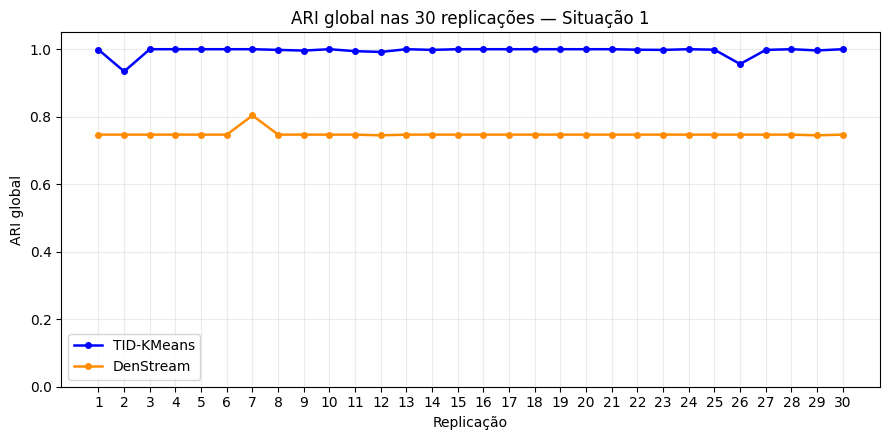

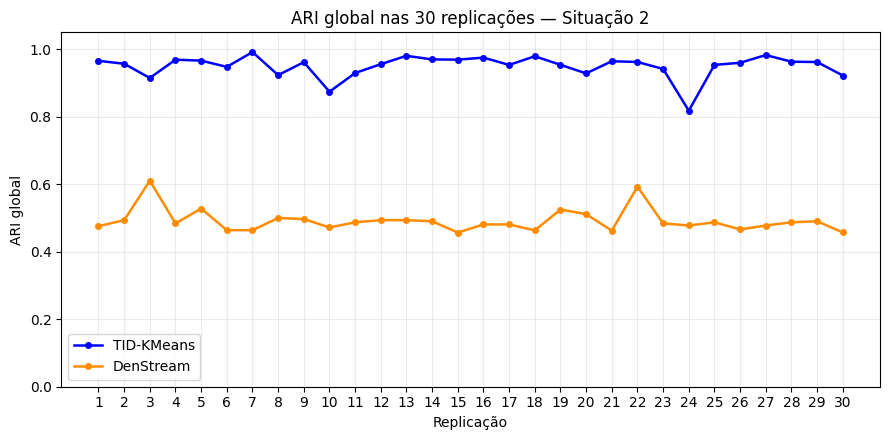

In [69]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cores = {
    "TID-KMeans": "blue",
    "DenStream": "darkorange"
}

metodos = ["TID-KMeans", "DenStream"]
situacoes = ["Situação 1", "Situação 2"]

for situacao in situacoes:
    dados = df_resultados[
        df_resultados["Situação"] == situacao
    ]

    fig, ax = plt.subplots(figsize=(9, 4.5))

    for metodo in metodos:
        parte = dados[
            dados["Método"] == metodo
        ].sort_values("Replicação")

        ax.plot(
            parte["Replicação"],
            parte["ARI_global"],
            marker="o",
            markersize=4,
            linewidth=1.8,
            color=cores[metodo],
            label=metodo
        )

    ax.set_title(
        f"ARI global nas 30 replicações — {situacao}"
    )
    ax.set_xlabel("Replicação")
    ax.set_ylabel("ARI global")
    ax.set_xticks(range(1, 31))
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)
    ax.legend()

    plt.tight_layout()

    fig.savefig(
        f"ari_global_{situacao.replace(' ', '_')}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


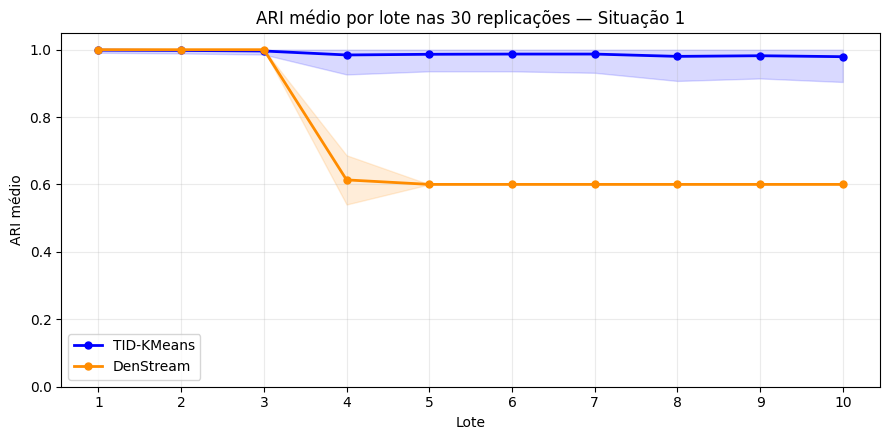

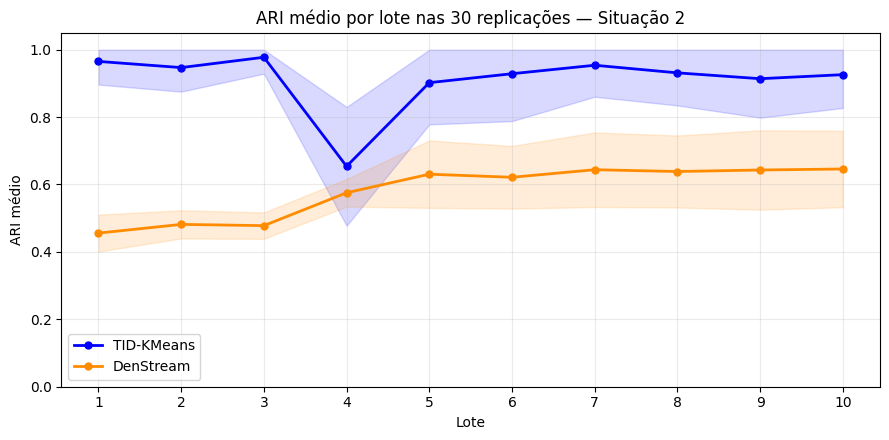

In [68]:

resumo_lotes = (
    df_detalhados
    .groupby(["Situação", "Método", "Lote"])["ARI"]
    .agg(media="mean", desvio="std")
    .reset_index()
)

for situacao in situacoes:
    dados = resumo_lotes[
        resumo_lotes["Situação"] == situacao
    ]

    fig, ax = plt.subplots(figsize=(9, 4.5))

    for metodo in metodos:
        parte = dados[
            dados["Método"] == metodo
        ].sort_values("Lote")

        lotes = parte["Lote"].to_numpy()
        media = parte["media"].to_numpy()
        desvio = parte["desvio"].fillna(0).to_numpy()

        ax.plot(
            lotes,
            media,
            marker="o",
            markersize=5,
            linewidth=2,
            color=cores[metodo],
            label=metodo
        )

        ax.fill_between(
            lotes,
            np.clip(media - desvio, -1, 1),
            np.clip(media + desvio, -1, 1),
            color=cores[metodo],
            alpha=0.15
        )

    ax.set_title(
        f"ARI médio por lote nas 30 replicações — {situacao}"
    )
    ax.set_xlabel("Lote")
    ax.set_ylabel("ARI médio")
    ax.set_xticks(range(1, 11))
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)
    ax.legend()

    plt.tight_layout()

    fig.savefig(
        f"ari_medio_lotes_{situacao.replace(' ', '_')}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


---
# Aplicação aos dados reais: Occupancy Detection

Este bloco é independente das bases simuladas e utiliza os arquivos originais de ocupação. O `StandardScaler` é ajustado apenas na amostra inicial. As funções com nomes `avaliar_dynamic_kmeans` / `avaliar_denstream` abaixo são específicas desta aplicação; as funções das simulações são `avaliar_tid_sim` / `avaliar_denstream_sim`.

In [1]:
# %% 0. Imports e configuração
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler

# True = grades pequenas, só para testar se o código roda de ponta a ponta
RAPIDO = False

# Caminhos dos arquivos (ajuste se necessário)
ARQ_X0 = "datatest.txt"
ARQ_CAL = "datatraining.txt"
ARQ_TESTE = "datatest2.txt"

# Variáveis usadas na clusterização
COLS = [
    "Temperature",
    "Light",
    "CO2",
    "Humidity"
]

TAM_LOTE = 60          # 1 ponto = 1 minuto, então 60 = 1 hora
JANELA_ARI = 4320      # 3 dias (janela que sempre contém as duas classes)


In [2]:
# %% 1. Leitura e junção dos arquivos
partes = []
for arq in [ARQ_X0, ARQ_CAL, ARQ_TESTE]:
    d = pd.read_csv(arq, index_col=0)   # 1ª coluna é um índice sem nome no cabeçalho
    d["origem"] = arq
    partes.append(d)

df = pd.concat(partes)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

print("Formato:", df.shape, "(esperado: 20560 linhas)")
print("Ordenado no tempo:", df["date"].is_monotonic_increasing)
print("Nulos:", int(df.isna().sum().sum()))
print(df.groupby("origem")["date"].agg(["min", "max", "count"]))


Formato: (20560, 8) (esperado: 20560 linhas)
Ordenado no tempo: True
Nulos: 0
                                 min                 max  count
origem                                                         
datatest.txt     2015-02-02 14:19:00 2015-02-04 10:43:00   2665
datatest2.txt    2015-02-11 14:48:00 2015-02-18 09:19:00   9752
datatraining.txt 2015-02-04 17:51:00 2015-02-10 09:33:00   8143


In [3]:
# %% 2. Preparação: X0, calibração, teste, scaler e tempo
base = df[df["origem"] == ARQ_X0]
cal = df[df["origem"] == ARQ_CAL]
teste = df[df["origem"] == ARQ_TESTE]

# Scaler ajustado SÓ em X0 (sem vazamento do fluxo)
scaler = StandardScaler().fit(base[COLS])

# Tempo 0 = último instante de X0. O tempo dos lotes é medido em DIAS a partir daí,
# o que mantém o decaimento do DynamicKMeans (ultimo_tempo = 0) consistente.
T0 = base["date"].iloc[-1]


def montar(d):
    """Padroniza as variáveis e acrescenta 'Grupo' (rótulo) e 'tempo' (dias desde T0)."""
    out = pd.DataFrame(scaler.transform(d[COLS]), columns=COLS, index=d.index)
    out["Grupo"] = d["Occupancy"].values
    out["tempo"] = (d["date"] - T0).dt.total_seconds().values / 86400.0
    return out


df_base = montar(base).reset_index(drop=True)
fluxo_cal = montar(cal).reset_index(drop=True)
fluxo = montar(pd.concat([cal, teste])).reset_index(drop=True)   # calibração + teste, contínuo
N_CAL = len(cal)                                                 # primeiros N_CAL pontos do fluxo

print(f"X0: {len(df_base)} | calibração: {N_CAL} | teste: {len(fluxo) - N_CAL}")
print("Primeiro tempo do fluxo (dias):", round(float(fluxo['tempo'].iloc[0]), 3))


def fatiar(f, n):
    """Divide o fluxo em lotes consecutivos de n pontos."""
    return [f.iloc[i:i + n] for i in range(0, len(f), n)]


X0: 2665 | calibração: 8143 | teste: 9752
Primeiro tempo do fluxo (dias): 0.297


In [4]:
# %% 3. DynamicKMeans usado na aplicação real (implementação e avaliadores independentes)
class DynamicKMeans:

    def __init__(
        self,
        n_clusters,
        lambda_decay=0.1,
        fator_limiar=1.5
    ):

        self.n_clusters = n_clusters
        self.lambda_decay = lambda_decay
        self.fator_limiar = fator_limiar

        # Tempo do último lote processado
        self.ultimo_tempo = 0

    # ==================================================
    # FASE INICIAL: K-MEANS
    # ==================================================

    def fit_initial(self, X0):

        kmeans = KMeans(
            n_clusters=self.n_clusters,
            random_state=123,
            n_init=50
        )

        labels = kmeans.fit_predict(X0)

        self.labels_initial = labels
        self.clusters = []

        # Informações iniciais de cada cluster
        for j in range(self.n_clusters):

            pontos_cluster = X0[labels == j]

            N_j = len(pontos_cluster)

            LS_j = pontos_cluster.sum(axis=0)

            c_j = LS_j / N_j

            # Distâncias ao centróide
            distancias = np.linalg.norm(
                pontos_cluster - c_j,
                axis=1
            )

            # Limiar específico do cluster
            # Utiliza o fator definido na inicialização
            D_j = self.fator_limiar * distancias.max()

            self.clusters.append({
                "LS": LS_j,
                "N": N_j,
                "centroide": c_j,
                "limiar": D_j
            })

        # Média dos limiares iniciais
        self.limiar_medio = np.mean([
            c["limiar"] for c in self.clusters
        ])

        # A base inicial corresponde ao tempo 0
        self.ultimo_tempo = 0

    # ==================================================
    # DECAIMENTO TEMPORAL DE TODOS OS CLUSTERS
    # ==================================================

    def aplicar_decaimento(self, tempo_atual):

        # Diferença em dias desde o último lote
        delta_t = tempo_atual - self.ultimo_tempo

        if delta_t < 0:
            raise ValueError(
                "O tempo atual não pode ser menor "
                "que o tempo do último lote processado."
            )

        # Fator de decaimento
        peso = 2.0 ** (
            -self.lambda_decay * delta_t
        )

        # Aplicar decaimento em TODOS os clusters
        for cluster in self.clusters:

            cluster["LS"] *= peso
            cluster["N"] *= peso

            # Atualizar centróide
            cluster["centroide"] = (
                cluster["LS"] / cluster["N"]
            )

        # Atualiza o tempo global do fluxo
        self.ultimo_tempo = tempo_atual

    # ==================================================
    # PROCESSAR UM LOTE
    # ==================================================

    def process_batch(self, X_batch, tempo):

        # 1. Aplicar decaimento em todos os clusters
        self.aplicar_decaimento(tempo)

        labels_pred = []

        # 2. Inserir as observações do lote
        for x_t in X_batch:

            label = self.process_one(x_t)

            labels_pred.append(label)

        return np.array(labels_pred)

    # ==================================================
    # PROCESSAR UMA OBSERVAÇÃO
    # ==================================================

    def process_one(self, x_t):

        # Calcular distância aos centróides atuais
        distancias = []

        for idx, cluster in enumerate(self.clusters):

            d = np.linalg.norm(
                x_t - cluster["centroide"]
            )

            distancias.append((idx, d))

        # Ordenar pela menor distância
        distancias.sort(key=lambda x: x[1])

        # Tentar inserir no cluster mais próximo
        for idx, d in distancias:

            cluster = self.clusters[idx]

            if d <= cluster["limiar"]:

                # Acrescentar a observação
                cluster["LS"] += x_t
                cluster["N"] += 1

                # Atualizar centróide
                cluster["centroide"] = (
                    cluster["LS"] / cluster["N"]
                )

                return idx

        # Nenhum cluster aceitou a observação:
        # criar um novo cluster
        novo_cluster = {
            "LS": x_t.copy(),
            "N": 1.0,
            "centroide": x_t.copy(),
            "limiar": self.limiar_medio
        }

        self.clusters.append(novo_cluster)

        return len(self.clusters) - 1

    # ==================================================
    # FUNÇÕES AUXILIARES
    # ==================================================

    def get_centroids(self):

        return np.array([
            c["centroide"] for c in self.clusters
        ])

    def get_number_clusters(self):

        return len(self.clusters)

    def get_cluster_info(self):

        return self.clusters

# %% 3b. Funções auxiliares e de avaliação (código original + retorno das predições)
def obter_variaveis(df_):
    """Retorna somente as variáveis usadas na clusterização."""
    colunas_excluir = ["Grupo", "tempo"]
    return df_.drop(columns=colunas_excluir, errors="ignore")


def obter_centros_denstream(modelo, colunas):
    """
    Obtém os centros dos p-micro-clusters do DenStream,
    na mesma ordem das colunas usadas como atributos.
    """
    centros = []

    for mc in modelo.p_micro_clusters.values():
        centro = mc.calc_center(modelo.timestamp)

        vetor = np.array(
            [centro.get(coluna, 0.0) for coluna in colunas],
            dtype=float
        )

        centros.append(vetor)

    if len(centros) == 0:
        return np.empty((0, len(colunas)))

    return np.vstack(centros)


def alinhar_rotulos_denstream(
    centros_atuais,
    centros_anteriores,
    ids_anteriores,
    proximo_id,
    distancia_maxima
):
    """
    Tenta manter IDs de clusters consistentes entre lotes,
    associando centros atuais aos centros anteriores por
    distância mínima.

    Centros sem correspondência recebem novos IDs.
    """
    n_atual = len(centros_atuais)
    ids_atuais = np.full(n_atual, -1, dtype=int)

    if n_atual == 0:
        return ids_atuais, proximo_id

    if len(centros_anteriores) > 0:
        distancias = cdist(centros_atuais, centros_anteriores)

        linhas, colunas = linear_sum_assignment(distancias)

        for i_atual, i_anterior in zip(linhas, colunas):
            if distancias[i_atual, i_anterior] <= distancia_maxima:
                ids_atuais[i_atual] = ids_anteriores[i_anterior]

    for i in range(n_atual):
        if ids_atuais[i] == -1:
            ids_atuais[i] = proximo_id
            proximo_id += 1

    return ids_atuais, proximo_id


def predizer_por_centros(X, centros):
    """Associa cada observação ao centro mais próximo."""
    if len(centros) == 0:
        raise ValueError(
            "O DenStream não possui p-micro-clusters "
            "disponíveis para realizar a predição."
        )

    distancias = cdist(X, centros)
    return distancias.argmin(axis=1)


def avaliar_dynamic_kmeans(
    df_base, lotes, lambda_decay, fator_limiar, n_clusters=2
):
    X0 = obter_variaveis(df_base).to_numpy(dtype=float)
    y0 = df_base["Grupo"].to_numpy()

    modelo = DynamicKMeans(
        n_clusters,
        lambda_decay=lambda_decay,
        fator_limiar=fator_limiar
    )

    modelo.fit_initial(X0)

    # Avaliação da base inicial
    pred_inicial = modelo.labels_initial
    ari_inicial = adjusted_rand_score(y0, pred_inicial)

    # Armazenamento dos resultados
    resultados_lotes = []
    y_true_stream = []
    y_pred_stream = []

    y_true_global = list(y0)
    y_pred_global = list(pred_inicial)

    # Processamento dos lotes
    for i, lote in enumerate(lotes, start=1):
        X_lote = obter_variaveis(lote).to_numpy(dtype=float)
        y_lote = lote["Grupo"].to_numpy()

        tempo_lote = (
            lote["tempo"].iloc[0]
            if "tempo" in lote.columns
            else i
        )

        pred = modelo.process_batch(X_lote, tempo_lote)

        ari_lote = adjusted_rand_score(y_lote, pred)

        resultados_lotes.append({
            "Lote": i,
            "Tempo": tempo_lote,
            "ARI": ari_lote,
            "Numero_clusters": modelo.get_number_clusters()
        })

        y_true_stream.extend(y_lote)
        y_pred_stream.extend(pred)

        y_true_global.extend(y_lote)
        y_pred_global.extend(pred)

    # ARI considerando somente as observações do fluxo
    ari_stream = adjusted_rand_score(
        y_true_stream, y_pred_stream
    )

    # ARI incluindo a base inicial e todo o fluxo
    ari_global = adjusted_rand_score(
        y_true_global, y_pred_global
    )

    return {
        "ARI_inicial": ari_inicial,
        "ARI_stream": ari_stream,
        "ARI_global_com_base": ari_global,
        "ARI_lotes": resultados_lotes,
        "Numero_clusters_final": modelo.get_number_clusters(),
        # --- acrescentado: predições para avaliar por trecho ---
        "y_true_stream": np.array(y_true_stream),
        "y_pred_stream": np.array(y_pred_stream),
    }


def avaliar_denstream(df_base, lotes, config):
    from river import cluster as river_cluster   # import local: só exige river aqui

    # ------------------------------------------------------
    # 1. Inicializar e treinar com a base inicial
    # ------------------------------------------------------

    X0_df = obter_variaveis(df_base)
    colunas = list(X0_df.columns)

    X0 = X0_df.to_numpy(dtype=float)
    y0 = df_base["Grupo"].to_numpy()

    modelo = river_cluster.DenStream(
        epsilon=config["epsilon"],
        beta=config["beta"],
        mu=config["mu"],
        decaying_factor=config["decaying_factor"],
        n_samples_init=config["n_samples_init"],
        stream_speed=config["stream_speed"]
    )

    # O River recebe cada observação como um dicionário
    for registro in X0_df.to_dict(orient="records"):
        modelo.learn_one(registro)

    # Centros disponíveis após o treinamento inicial
    centros = obter_centros_denstream(modelo, colunas)

    if len(centros) == 0:
        raise ValueError(
            "O DenStream não formou p-micro-clusters "
            "após o treinamento inicial."
        )

    # IDs iniciais dos clusters
    ids_centros = np.arange(len(centros), dtype=int)
    proximo_id = len(centros)

    # Avaliação retrospectiva da base inicial
    pred_inicial = predizer_por_centros(X0, centros)
    ari_inicial = adjusted_rand_score(y0, pred_inicial)

    y_true_global = list(y0)
    y_pred_global = list(ids_centros[pred_inicial])

    y_true_stream = []
    y_pred_stream = []
    resultados_lotes = []

    # ------------------------------------------------------
    # 2. Processar o fluxo lote a lote
    # ------------------------------------------------------

    for i, lote in enumerate(lotes, start=1):

        X_lote_df = obter_variaveis(lote)
        X_lote = X_lote_df.to_numpy(dtype=float)
        y_lote = lote["Grupo"].to_numpy()

        tempo_lote = (
            lote["tempo"].iloc[0]
            if "tempo" in lote.columns
            else i
        )

        # Predizer usando os centros disponíveis ANTES
        # de aprender as observações deste lote
        pred_indices = predizer_por_centros(X_lote, centros)
        pred = ids_centros[pred_indices]

        ari_lote = adjusted_rand_score(y_lote, pred)

        y_true_stream.extend(y_lote)
        y_pred_stream.extend(pred)

        y_true_global.extend(y_lote)
        y_pred_global.extend(pred)

        # Aprender as observações do lote, uma a uma
        for registro in X_lote_df.to_dict(orient="records"):
            modelo.learn_one(registro)

        # Obter os centros atualizados para o próximo lote
        centros_novos = obter_centros_denstream(modelo, colunas)

        if len(centros_novos) > 0:

            ids_novos, proximo_id = alinhar_rotulos_denstream(
                centros_atuais=centros_novos,
                centros_anteriores=centros,
                ids_anteriores=ids_centros,
                proximo_id=proximo_id,
                distancia_maxima=config["epsilon"]
            )

            centros = centros_novos
            ids_centros = ids_novos

        # Quantidade de p-micro-clusters após aprender o lote
        resultados_lotes.append({
            "Lote": i,
            "Tempo": tempo_lote,
            "ARI": ari_lote,
            "Numero_clusters": len(modelo.p_micro_clusters)
        })

    # ------------------------------------------------------
    # 3. Calcular os resultados gerais
    # ------------------------------------------------------

    ari_stream = adjusted_rand_score(
        y_true_stream,
        y_pred_stream
    )

    ari_global = adjusted_rand_score(
        y_true_global,
        y_pred_global
    )

    return {
        "ARI_inicial": ari_inicial,
        "ARI_stream": ari_stream,
        "ARI_global_com_base": ari_global,
        "ARI_lotes": resultados_lotes,
        "Numero_clusters_final": len(modelo.p_micro_clusters),
        # --- acrescentado: predições para avaliar por trecho ---
        "y_true_stream": np.array(y_true_stream),
        "y_pred_stream": np.array(y_pred_stream),
    }


## 7. Seleção e avaliação temporal — Occupancy

Mantida a rotina principal que seleciona na calibração e avalia no teste. A busca do DenStream inclui `beta`, conforme a configuração final do TCC.

In [8]:
# ============================================================
# 1. CONFIGURAÇÕES
# ============================================================

SEMENTE = 123
RAPIDO = False

TAM_LOTE = 60
JANELA = 360
PASSO = 360

# Mínimo de janelas com silhueta definida.
MIN_FRAC_VALIDAS = 0.40

# Máximo de estruturas ao final da calibração.
MAX_CLUSTERS = 15

# Para não escolher valores usando o teste.
GRADE_K = [2, 3, 4]

GRADE_ALPHA = [
    0.50, 0.75, 1.00, 1.25,
    1.50, 1.70, 2.00
]

# Tempo medido em dias.
# lambda=0 significa ausência de decaimento.
GRADE_LAMBDA = [0, 0.5, 1, 2, 5]

GRADE_EPS = [0.3, 0.5, 0.75, 1.0]
GRADE_MU = [2, 5, 8]
GRADE_MEIA = [0.5, 1, 3]

if RAPIDO:
    GRADE_K = [2, 3]
    GRADE_ALPHA = [0.75, 1.5]
    GRADE_LAMBDA = [0, 1, 5]
    GRADE_EPS = [0.5, 1.0]
    GRADE_MU = [2, 5]
    GRADE_MEIA = [1]


In [9]:
# ============================================================
# 2. PREPARAÇÃO E VERIFICAÇÕES
# ============================================================

X0 = obter_variaveis(df_base).to_numpy(float)
Xcal = obter_variaveis(fluxo_cal).to_numpy(float)
Xflux = obter_variaveis(fluxo).to_numpy(float)

ycal = fluxo_cal["Grupo"].to_numpy()
yflux = fluxo["Grupo"].to_numpy()

N_CAL = len(fluxo_cal)

Xteste = Xflux[N_CAL:]
yteste = yflux[N_CAL:]

lotes_cal = fatiar(fluxo_cal, TAM_LOTE)
lotes_flux = fatiar(fluxo, TAM_LOTE)

COLUNAS = list(obter_variaveis(df_base).columns)

assert np.isfinite(X0).all()
assert np.isfinite(Xcal).all()
assert np.isfinite(Xflux).all()
assert len(Xflux) == len(yflux)

assert np.all(
    np.diff(fluxo["tempo"].to_numpy()) >= 0
)

print("Inicialização:", len(X0))
print("Calibração:", len(Xcal))
print("Teste:", len(Xteste))
print("Variáveis:", COLUNAS)


Inicialização: 2665
Calibração: 8143
Teste: 9752
Variáveis: ['Temperature', 'Light', 'CO2', 'Humidity']


In [10]:
# ============================================================
# 3. FUNÇÕES DE MÉTRICAS TEMPORAIS
# ============================================================

def janelas_indices(n, janela=JANELA, passo=PASSO):
    return [
        (i, i + janela)
        for i in range(0, n - janela + 1, passo)
    ]


def sil_seguro(X, pred):
    pred = np.asarray(pred)
    n_grupos = len(np.unique(pred))

    if not 2 <= n_grupos < len(pred):
        return np.nan

    return float(silhouette_score(X, pred))


def metricas_janelas(X, y, pred):
    """
    Uma linha por janela.

    A silhueta é indefinida quando existe um
    único cluster.

    ARI informativo: somente com pelo menos
    duas classes reais e dois clusters estimados.
    """
    linhas = []

    for i, j in janelas_indices(len(y)):
        Xw = X[i:j]
        yw = y[i:j]
        pw = pred[i:j]

        n_classes = len(np.unique(yw))
        n_clusters = len(np.unique(pw))

        sil = sil_seguro(Xw, pw)

        ari = np.nan
        if n_classes >= 2 and n_clusters >= 2:
            ari = adjusted_rand_score(yw, pw)

        linhas.append({
            "inicio": i,
            "fim": j,
            "silhueta": sil,
            "ARI_informativo": ari,
            "n_classes": n_classes,
            "n_clusters": n_clusters,
            "frac_ocupada": np.mean(yw == 1),
            "sil_valida": np.isfinite(sil),
            "ari_valido": np.isfinite(ari)
        })

    return pd.DataFrame(linhas)


def resumir_janelas(X, y, pred):
    j = metricas_janelas(X, y, pred)

    return {
        "silhueta": j["silhueta"].mean(),
        "frac_sil_valida": j["sil_valida"].mean(),
        "frac_ari_valido": j["ari_valido"].mean(),
        "ARI_janelas": j["ARI_informativo"].mean(),
        "n_janelas": len(j)
    }


def selecionar_grade(tabela):
    """
    Seleção exclusivamente por critérios internos:
    silhueta, proporção de janelas válidas e
    número de estruturas.

    Não utiliza ARI nem rótulos reais.
    """
    elegiveis = tabela.loc[
        tabela["silhueta_cal"].notna()
        &
        (tabela["frac_validas"] >= MIN_FRAC_VALIDAS)
        &
        (tabela["clusters_cal"] <= MAX_CLUSTERS)
    ].copy()

    if elegiveis.empty:
        raise ValueError(
            "Nenhuma configuração satisfez os limites. "
            "Inspecione a grade antes de alterá-los."
        )

    return elegiveis.sort_values(
        [
            "silhueta_cal",
            "frac_validas",
            "clusters_cal"
        ],
        ascending=[False, False, True]
    ).iloc[0]


In [12]:
# ============================================================
# 4. DIAGNÓSTICO DAS JANELAS REAIS
# ============================================================

print("\n=== Composição temporal da ocupação ===")

linhas = []

for trecho, y in [
    ("Calibração", ycal),
    ("Teste", yteste)
]:
    for i, j in janelas_indices(len(y)):
        valores = y[i:j]

        linhas.append({
            "trecho": trecho,
            "inicio": i,
            "fim": j,
            "frac_ocupada": np.mean(valores == 1),
            "duas_classes": len(np.unique(valores)) == 2
        })

diag_ocupacao = pd.DataFrame(linhas)

print(
    diag_ocupacao.groupby("trecho").agg(
        janelas=("duas_classes", "size"),
        frac_duas_classes=("duas_classes", "mean"),
        ocupacao_media=("frac_ocupada", "mean")
    ).round(4)
)



=== Composição temporal da ocupação ===
            janelas  frac_duas_classes  ocupacao_media
trecho                                                
Calibração       22             0.4545          0.2115
Teste            27             0.4444          0.2099


In [13]:
# ============================================================
# 5. ESCOLHA DE K EM X0
# ============================================================

print("\n=== Seleção do K inicial ===")

reg_k = []

for k in GRADE_K:
    km = KMeans(
        n_clusters=k,
        n_init=50,
        random_state=SEMENTE
    )

    labels = km.fit_predict(X0)

    reg_k.append({
        "K": k,
        "silhueta_X0": silhouette_score(X0, labels),
        "inercia": km.inertia_
    })

tabela_k = pd.DataFrame(reg_k)

print(tabela_k.round(4).to_string(index=False))

K_ESC = int(
    tabela_k.sort_values(
        "silhueta_X0",
        ascending=False
    ).iloc[0]["K"]
)

print("K selecionado:", K_ESC)



=== Seleção do K inicial ===
 K  silhueta_X0   inercia
 2       0.6222 3254.4409
 3       0.4930 2516.5430
 4       0.4670 1912.1220
K selecionado: 2


In [14]:
import itertools

# ============================================================
# 6. CALIBRAÇÃO DO DYNAMIC K-MEANS
# ============================================================

print("\n=== Calibração Dynamic K-Means ===")

reg_dyn = []

for lam, alpha in itertools.product(
    GRADE_LAMBDA,
    GRADE_ALPHA
):
    r = avaliar_dynamic_kmeans(
        df_base,
        lotes_cal,
        lambda_decay=lam,
        fator_limiar=alpha,
        n_clusters=K_ESC
    )

    pred = np.asarray(r["y_pred_stream"])

    m = resumir_janelas(Xcal, ycal, pred)

    reg_dyn.append({
        "lambda": lam,
        "alpha": alpha,
        "silhueta_cal": m["silhueta"],
        "frac_validas": m["frac_sil_valida"],
        "clusters_cal": r["Numero_clusters_final"],
        "ARI_cal_aux": r["ARI_stream"]
    })

grade_dyn = pd.DataFrame(reg_dyn)

print(
    grade_dyn.sort_values(
        "silhueta_cal",
        ascending=False
    ).round(4).to_string(index=False)
)

esc_dyn = selecionar_grade(grade_dyn)

print("\nDynamic selecionado:")
print(esc_dyn.to_string())



=== Calibração Dynamic K-Means ===
 lambda  alpha  silhueta_cal  frac_validas  clusters_cal  ARI_cal_aux
    5.0   2.00        0.6611        0.1818             2       0.2591
    5.0   1.00        0.6473        0.2727             3       0.2344
    2.0   1.25        0.6459        0.2273             2       0.0039
    5.0   0.75        0.6409        0.5000             5       0.1523
    2.0   1.00        0.6265        0.3636             4       0.0286
    2.0   1.70        0.6220        0.2727             2       0.4427
    2.0   2.00        0.6220        0.2727             2       0.4427
    5.0   1.50        0.6072        0.2727             2       0.4210
    5.0   1.25        0.5965        0.2727             2       0.4261
    2.0   1.50        0.5942        0.2273             2       0.0082
    0.5   1.00        0.5936        0.5000             4       0.0340
    5.0   1.70        0.5793        0.2727             2       0.4029
    0.0   2.00        0.5761        0.2727            

In [15]:
# ============================================================
# 7. CALIBRAÇÃO DO DENSTREAM
# ============================================================

print("\n=== Calibração DenStream ===")

# Mantém a parametrização utilizada anteriormente.
# A meia-vida é aproximada em número de observações,
# pois o River usa relógio interno, não datas reais.

STREAM_SPEED = 60


def config_den(eps, mu, meia_vida):
    return {
        "epsilon": float(eps),
        "beta": 0.75,
        "mu": int(mu),
        "decaying_factor": (
            STREAM_SPEED / (1440.0 * float(meia_vida))
        ),
        "n_samples_init": min(1000, len(df_base)),
        "stream_speed": STREAM_SPEED
    }

# A calibração completa, incluindo beta, é realizada na próxima célula.


# Função disponível antes da seleção do DenStream
def selecionar_configuracao(
    tabela,
    minimo_validas=0.40,
    max_clusters=15
):

    candidatos = tabela.loc[
        tabela["silhueta_cal"].notna()
        &
        (tabela["frac_validas"] >= minimo_validas)
        &
        (tabela["clusters_cal"] <= max_clusters)
    ].copy()

    if candidatos.empty:
        raise ValueError(
            "Nenhuma configuração atende aos critérios."
        )

    candidatos = candidatos.sort_values(
        [
            "silhueta_cal",
            "frac_validas",
            "clusters_cal"
        ],
        ascending=[False, False, True]
    )

    return candidatos.iloc[0]




=== Calibração DenStream ===


In [19]:
import itertools

# ============================================================
# CALIBRAÇÃO DENSTREAM — INCLUINDO BETA
# ============================================================

import itertools
import numpy as np
import pandas as pd

GRADE_BETA = [0.25, 0.50, 0.75]

reg_den_beta = []

for eps, mu, meia, beta in itertools.product(
    GRADE_EPS, GRADE_MU, GRADE_MEIA, GRADE_BETA
):

    # Restrição usual do DenStream
    if beta * mu <= 1:
        continue

    cfg = config_den(eps, mu, meia)
    cfg["beta"] = float(beta)

    try:
        r = avaliar_denstream(
            df_base,
            lotes_cal,
            cfg
        )

        pred = np.asarray(r["y_pred_stream"])
        m = resumir_janelas(Xcal, ycal, pred)

        reg_den_beta.append({
            "epsilon": eps,
            "mu": mu,
            "beta": beta,
            "meia_vida": meia,
            "silhueta_cal": m["silhueta"],
            "frac_validas": m["frac_sil_valida"],
            "clusters_cal": r["Numero_clusters_final"],
            "ARI_cal_aux": r["ARI_stream"]
        })

    except ValueError as erro:
        print("Ignorada:", cfg, erro)

grade_den_beta = pd.DataFrame(reg_den_beta)

print("\n=== MELHORES CONFIGURAÇÕES ===")
print(
    grade_den_beta.sort_values(
        "silhueta_cal",
        ascending=False
    ).head(15).round(4).to_string(index=False)
)

# Seleção com o mesmo critério anterior
den_beta_40 = selecionar_configuracao(
    grade_den_beta,
    minimo_validas=0.40
)

print("\n=== DENSTREAM SELECIONADO ===")
print(den_beta_40.to_string())

# Atualizar as variáveis para as células seguintes
grade_den = grade_den_beta.copy()
esc_den = den_beta_40.copy()
den_40 = den_beta_40.copy()

# Comparação com a escolha anterior
print("\n=== COMPARAÇÃO ===")
print(
    "Beta escolhido:",
    float(esc_den["beta"])
)



=== MELHORES CONFIGURAÇÕES ===
 epsilon  mu  beta  meia_vida  silhueta_cal  frac_validas  clusters_cal  ARI_cal_aux
    0.75   8  0.50        0.5        0.5339        0.6364             4       0.2668
    0.75   5  0.75        0.5        0.5339        0.6364             4       0.2668
    0.50   2  0.75        0.5        0.5322        0.5909             6       0.2331
    0.50   5  0.25        0.5        0.5322        0.5909             7       0.2331
    0.50   5  0.75        1.0        0.5249        0.5909            11       0.2352
    0.50   8  0.50        0.5        0.5246        0.5909             7       0.1166
    0.50   5  0.75        0.5        0.5246        0.5909             7       0.1166
    0.50   2  0.75        3.0        0.5227        0.5909            16       0.2314
    0.50   5  0.50        1.0        0.5227        0.5909            13       0.2314
    0.50   5  0.25        3.0        0.5227        0.5909            16       0.2314
    0.50   5  0.75        3.0    

In [20]:
# ============================================================
# SELEÇÃO COM E SEM RESTRIÇÃO DE 40%
# ============================================================

import numpy as np
import pandas as pd



# Dynamic K-Means
dyn_40 = selecionar_configuracao(
    grade_dyn,
    minimo_validas=0.40
)

dyn_livre = selecionar_configuracao(
    grade_dyn,
    minimo_validas=0.0
)

# DenStream
den_40 = selecionar_configuracao(
    grade_den,
    minimo_validas=0.40
)

den_livre = selecionar_configuracao(
    grade_den,
    minimo_validas=0.0
)


print("\n=== Dynamic K-Means ===")

print("\nCom 40%:")
print(dyn_40.to_string())

print("\nSem restrição:")
print(dyn_livre.to_string())


print("\n=== DenStream ===")

print("\nCom 40%:")
print(den_40.to_string())

print("\nSem restrição:")
print(den_livre.to_string())



=== Dynamic K-Means ===

Com 40%:
lambda          5.000000
alpha           0.750000
silhueta_cal    0.640853
frac_validas    0.500000
clusters_cal    5.000000
ARI_cal_aux     0.152310

Sem restrição:
lambda          5.000000
alpha           2.000000
silhueta_cal    0.661142
frac_validas    0.181818
clusters_cal    2.000000
ARI_cal_aux     0.259051

=== DenStream ===

Com 40%:
epsilon         0.750000
mu              5.000000
beta            0.750000
meia_vida       0.500000
silhueta_cal    0.533864
frac_validas    0.636364
clusters_cal    4.000000
ARI_cal_aux     0.266833

Sem restrição:
epsilon         0.750000
mu              5.000000
beta            0.750000
meia_vida       0.500000
silhueta_cal    0.533864
frac_validas    0.636364
clusters_cal    4.000000
ARI_cal_aux     0.266833


In [21]:
# ============================================================
# 8. EXECUÇÃO FINAL — SEM USAR O TESTE NA SELEÇÃO
# ============================================================

print("\n=== Execução final ===")

km_estatico = KMeans(
    n_clusters=K_ESC,
    random_state=SEMENTE,
    n_init=50
).fit(X0)

pred_km = km_estatico.predict(Xflux)

res_dyn = avaliar_dynamic_kmeans(
    df_base,
    lotes_flux,
    lambda_decay=float(esc_dyn["lambda"]),
    fator_limiar=float(esc_dyn["alpha"]),
    n_clusters=K_ESC
)

cfg_den = config_den(
    esc_den["epsilon"],
    esc_den["mu"],
    esc_den["meia_vida"]
)
# Usar efetivamente o beta selecionado no grid de calibração.
cfg_den["beta"] = float(esc_den["beta"])

res_den = avaliar_denstream(
    df_base,
    lotes_flux,
    cfg_den
)

pred_dyn = np.asarray(res_dyn["y_pred_stream"])
pred_den = np.asarray(res_den["y_pred_stream"])

predicoes = {
    "K-Means estático": pred_km,
    "Dynamic K-Means": pred_dyn,
    "DenStream (micro)": pred_den
}



=== Execução final ===


In [22]:
# ============================================================
# 9. TABELA FINAL DE MÉTRICAS
# ============================================================

resultados = []

for nome, pred in predicoes.items():
    cal_pred = pred[:N_CAL]
    teste_pred = pred[N_CAL:]

    mc = resumir_janelas(Xcal, ycal, cal_pred)
    mt = resumir_janelas(Xteste, yteste, teste_pred)

    if nome == "K-Means estático":
        n_final = K_ESC
    elif nome == "Dynamic K-Means":
        n_final = res_dyn["Numero_clusters_final"]
    else:
        n_final = res_den["Numero_clusters_final"]

    resultados.append({
        "Método": nome,
        "Sil_cal": mc["silhueta"],
        "Sil_teste": mt["silhueta"],
        "Validas_cal": mc["frac_sil_valida"],
        "Validas_teste": mt["frac_sil_valida"],
        "ARI_cal": adjusted_rand_score(ycal, cal_pred),
        "ARI_teste": adjusted_rand_score(yteste, teste_pred),
        "ARI_janelas_teste": mt["ARI_janelas"],
        "Frac_ARI_validos": mt["frac_ari_valido"],
        "Clusters_finais": n_final
    })

tabela_final = pd.DataFrame(resultados)

print("\n=== Comparação final ===")
print(tabela_final.round(4).to_string(index=False))



=== Comparação final ===
           Método  Sil_cal  Sil_teste  Validas_cal  Validas_teste  ARI_cal  ARI_teste  ARI_janelas_teste  Frac_ARI_validos  Clusters_finais
 K-Means estático   0.5479     0.4987       0.3182         0.5556   0.4903     0.2776             0.5377            0.2963                2
  Dynamic K-Means   0.6409     0.5557       0.5000         0.5926   0.1523     0.2864             0.5592            0.3704                7
DenStream (micro)   0.5339     0.4258       0.6364         0.6667   0.2668     0.0820             0.3633            0.3704                3


In [23]:
# ============================================================
# 10. SILHUETA NAS MESMAS JANELAS
# ============================================================

print("\n=== Silhueta em janelas comuns ===")

# Primeiro, construímos as curvas separadamente,
# pois nenhuma janela deve atravessar a divisão
# entre calibração e teste.

curvas = {}

for nome, pred in predicoes.items():

    c = metricas_janelas(
        Xcal,
        ycal,
        pred[:N_CAL]
    )

    t = metricas_janelas(
        Xteste,
        yteste,
        pred[N_CAL:]
    )

    t["inicio"] += N_CAL
    t["fim"] += N_CAL

    curvas[nome] = {
        "cal": c,
        "teste": t
    }


def comparar_janelas_comuns(trecho):
    tabelas = []

    for nome, d in curvas.items():
        z = d[trecho][
            ["inicio", "fim", "silhueta"]
        ].copy()

        z = z.rename(
            columns={"silhueta": nome}
        )

        z = z.set_index(["inicio", "fim"])
        tabelas.append(z)

    conjunto = pd.concat(tabelas, axis=1)

    comuns = conjunto.dropna()

    print(f"\n{trecho.upper()}")
    print("Janelas totais:", len(conjunto))
    print("Janelas comuns válidas:", len(comuns))

    if comuns.empty:
        print("Nenhuma janela comum válida.")
        return conjunto, comuns

    resumo = pd.DataFrame({
        "Silhueta média comum": comuns.mean(),
        "DP entre janelas": comuns.std(),
        "Mediana": comuns.median()
    })

    print(resumo.round(4).to_string())

    return conjunto, comuns


sil_cal_todas, sil_cal_comuns = (
    comparar_janelas_comuns("cal")
)

sil_teste_todas, sil_teste_comuns = (
    comparar_janelas_comuns("teste")
)

# Comparação pareada: cada diferença corresponde
# à mesma janela temporal.
if not sil_teste_comuns.empty:

    referencia = sil_teste_comuns[
        "K-Means estático"
    ]

    for nome in [
        "Dynamic K-Means",
        "DenStream (micro)"
    ]:
        diferenca = sil_teste_comuns[nome] - referencia

        print(f"\n{nome} - K-Means estático")
        print("Diferença média:", round(diferenca.mean(), 4))
        print(
            "Fração das janelas em que supera:",
            round((diferenca > 0).mean(), 4)
        )



=== Silhueta em janelas comuns ===

CAL
Janelas totais: 22
Janelas comuns válidas: 7
                   Silhueta média comum  DP entre janelas  Mediana
K-Means estático                 0.5479            0.2772   0.6624
Dynamic K-Means                  0.6121            0.1102   0.6379
DenStream (micro)                0.5613            0.1729   0.6056

TESTE
Janelas totais: 27
Janelas comuns válidas: 10
                   Silhueta média comum  DP entre janelas  Mediana
K-Means estático                 0.5373            0.2030   0.5508
Dynamic K-Means                  0.6375            0.1394   0.6412
DenStream (micro)                0.4392            0.2244   0.4323

Dynamic K-Means - K-Means estático
Diferença média: 0.1002
Fração das janelas em que supera: 0.9

DenStream (micro) - K-Means estático
Diferença média: -0.0981
Fração das janelas em que supera: 0.3


In [24]:
# ============================================================
# MATRIZES DE CONFUSÃO — BASE DE TESTE
# Dynamic K-Means e DenStream
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score

for nome in ["Dynamic K-Means", "DenStream (micro)"]:

    # Predições somente da base de teste
    pred_teste = np.asarray(predicoes[nome])[N_CAL:]

    assert len(pred_teste) == len(yteste)

    matriz = pd.crosstab(
        pd.Series(yteste, name="Ocupação real"),
        pd.Series(pred_teste, name="Cluster estimado"),
        margins=True,
        margins_name="Total"
    )

    print(f"\n{'=' * 60}")
    print(f"MATRIZ DE CONFUSÃO — {nome}")
    print(f"{'=' * 60}")
    print(matriz.to_string())

    print(
        "\nARI teste:",
        round(adjusted_rand_score(yteste, pred_teste), 4)
    )
    print("Clusters no teste:", len(np.unique(pred_teste)))



MATRIZ DE CONFUSÃO — Dynamic K-Means
Cluster estimado     0     1    2     4    5  6  Total
Ocupação real                                         
0                 4781  1160  347   748  667  0   7703
1                    3    24  150  1859    9  4   2049
Total             4784  1184  497  2607  676  4   9752

ARI teste: 0.2864
Clusters no teste: 6

MATRIZ DE CONFUSÃO — DenStream (micro)
Cluster estimado     6   7    8   9  10   11    12   13   14    15   16  Total
Ocupação real                                                                 
0                 3258   7  322   5  26  331  1265  278  325  1034  852   7703
1                  282  91    0  36  34  509     0    0    0  1095    2   2049
Total             3540  98  322  41  60  840  1265  278  325  2129  854   9752

ARI teste: 0.082
Clusters no teste: 11


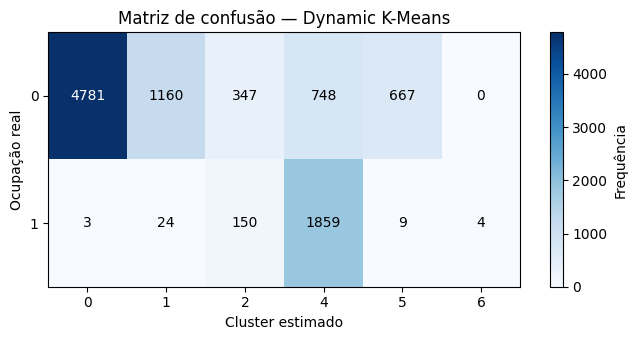

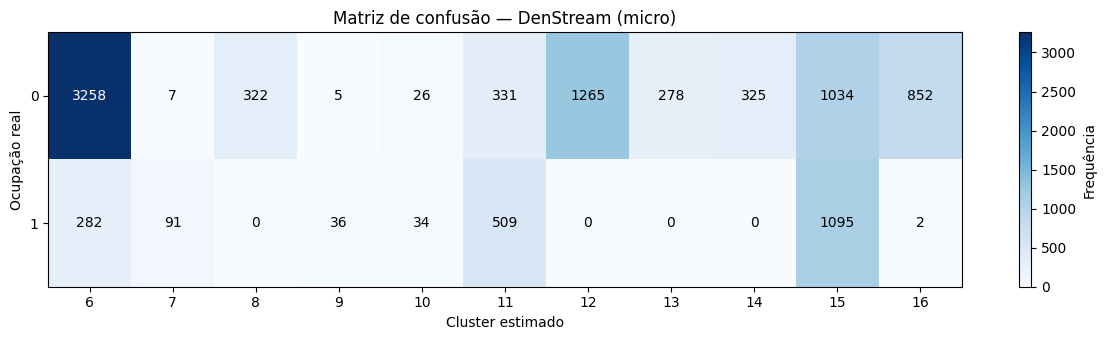

In [25]:
import matplotlib.pyplot as plt

for nome in ["Dynamic K-Means", "DenStream (micro)"]:

    pred_teste = np.asarray(predicoes[nome])[N_CAL:]

    matriz = pd.crosstab(
        pd.Series(yteste, name="Ocupação real"),
        pd.Series(pred_teste, name="Cluster estimado")
    )

    fig, ax = plt.subplots(
        figsize=(max(6, len(matriz.columns) * 1.1), 3.5)
    )

    im = ax.imshow(
        matriz.to_numpy(),
        aspect="auto",
        cmap="Blues"
    )

    ax.set_xticks(range(len(matriz.columns)))
    ax.set_xticklabels(matriz.columns)

    ax.set_yticks(range(len(matriz.index)))
    ax.set_yticklabels(matriz.index)

    ax.set_xlabel("Cluster estimado")
    ax.set_ylabel("Ocupação real")
    ax.set_title(f"Matriz de confusão — {nome}")

    for i in range(len(matriz.index)):
        for j in range(len(matriz.columns)):
            valor = int(matriz.iloc[i, j])
            cor_texto = "white" if valor > matriz.to_numpy().max() * 0.5 else "black"

            ax.text(
                j, i, str(valor),
                ha="center",
                va="center",
                color=cor_texto
            )

    plt.colorbar(im, ax=ax, label="Frequência")
    plt.tight_layout()
    plt.show()


In [41]:
# ============================================================
# 11. ABLACÃO DO DECAIMENTO
# ============================================================

print("\n=== Com e sem decaimento ===")

res_sem = avaliar_dynamic_kmeans(
    df_base,
    lotes_flux,
    lambda_decay=0.0,
    fator_limiar=float(esc_dyn["alpha"]),
    n_clusters=K_ESC
)

pred_sem = np.asarray(res_sem["y_pred_stream"])

ablacoes = {
    "Com decaimento": pred_dyn,
    "Sem decaimento": pred_sem
}

linhas_ab = []

for nome, pred in ablacoes.items():

    m = resumir_janelas(
        Xteste,
        yteste,
        pred[N_CAL:]
    )

    linhas_ab.append({
        "Método": nome,
        "Sil_teste": m["silhueta"],
        "Validas_teste": m["frac_sil_valida"],
        "ARI_teste": adjusted_rand_score(
            yteste, pred[N_CAL:]
        ),
        "Clusters_finais": (
            res_dyn["Numero_clusters_final"]
            if nome == "Com decaimento"
            else res_sem["Numero_clusters_final"]
        )
    })

tabela_ablacao = pd.DataFrame(linhas_ab)

print(tabela_ablacao.round(4).to_string(index=False))

# Silhueta pareada na ablação.
ab_com = metricas_janelas(
    Xteste,
    yteste,
    pred_dyn[N_CAL:]
)

ab_sem = metricas_janelas(
    Xteste,
    yteste,
    pred_sem[N_CAL:]
)

comparacao_ab = pd.DataFrame({
    "com": ab_com["silhueta"],
    "sem": ab_sem["silhueta"]
}).dropna()

print("\nJanelas válidas em ambas as versões:",
      len(comparacao_ab))

if not comparacao_ab.empty:
    dif = comparacao_ab["com"] - comparacao_ab["sem"]

    print("Silhueta média com:", comparacao_ab["com"].mean())
    print("Silhueta média sem:", comparacao_ab["sem"].mean())
    print("Diferença pareada:", dif.mean())
    print("Fração de vantagens:", (dif > 0).mean())



=== Com e sem decaimento ===
        Método  Sil_teste  Validas_teste  ARI_teste  Clusters_finais
Com decaimento     0.5557         0.5926     0.2864                7
Sem decaimento     0.4707         0.6667     0.1287               10

Janelas válidas em ambas as versões: 14
Silhueta média com: 0.5783974889973119
Silhueta média sem: 0.48729149375317826
Diferença pareada: 0.09110599524413368
Fração de vantagens: 0.7142857142857143


In [42]:
# ============================================================
# 12. TAMANHO E COMPOSIÇÃO DOS CLUSTERS
# ============================================================

print("\n=== Tamanho e composição dos clusters ===")

tabelas_composicao = {}

for nome, pred in predicoes.items():

    dados = pd.DataFrame({
        "Cluster": pred[N_CAL:],
        "Occupancy": yteste
    })

    tab = dados.groupby("Cluster").agg(
        n=("Occupancy", "size"),
        ocupados=("Occupancy", "sum"),
        proporcao_ocupados=("Occupancy", "mean")
    )

    tab["proporcao_total"] = (
        tab["n"] / len(dados)
    )

    tab = tab.sort_values(
        "n",
        ascending=False
    )

    tabelas_composicao[nome] = tab

    print("\n", nome)
    print(tab.round(4).to_string())

    # Cobertura dos clusters quase puros,
    # evitando avaliar somente porcentagens.
    for classe in [0, 1]:
        if classe == 1:
            selecionados = tab[
                tab["proporcao_ocupados"] >= 0.90
            ]
        else:
            selecionados = tab[
                tab["proporcao_ocupados"] <= 0.10
            ]

        print(
            f"Observações em clusters >=90% "
            f"da classe {classe}:",
            int(selecionados["n"].sum())
        )



=== Tamanho e composição dos clusters ===

 K-Means estático
            n  ocupados  proporcao_ocupados  proporcao_total
Cluster                                                     
1        5537        60              0.0108           0.5678
0        4215      1989              0.4719           0.4322
Observações em clusters >=90% da classe 0: 5537
Observações em clusters >=90% da classe 1: 0

 Dynamic K-Means
            n  ocupados  proporcao_ocupados  proporcao_total
Cluster                                                     
0        4784         3              0.0006           0.4906
4        2607      1859              0.7131           0.2673
1        1184        24              0.0203           0.1214
5         676         9              0.0133           0.0693
2         497       150              0.3018           0.0510
6           4         4              1.0000           0.0004
Observações em clusters >=90% da classe 0: 6644
Observações em clusters >=90% da classe 1: 4

 

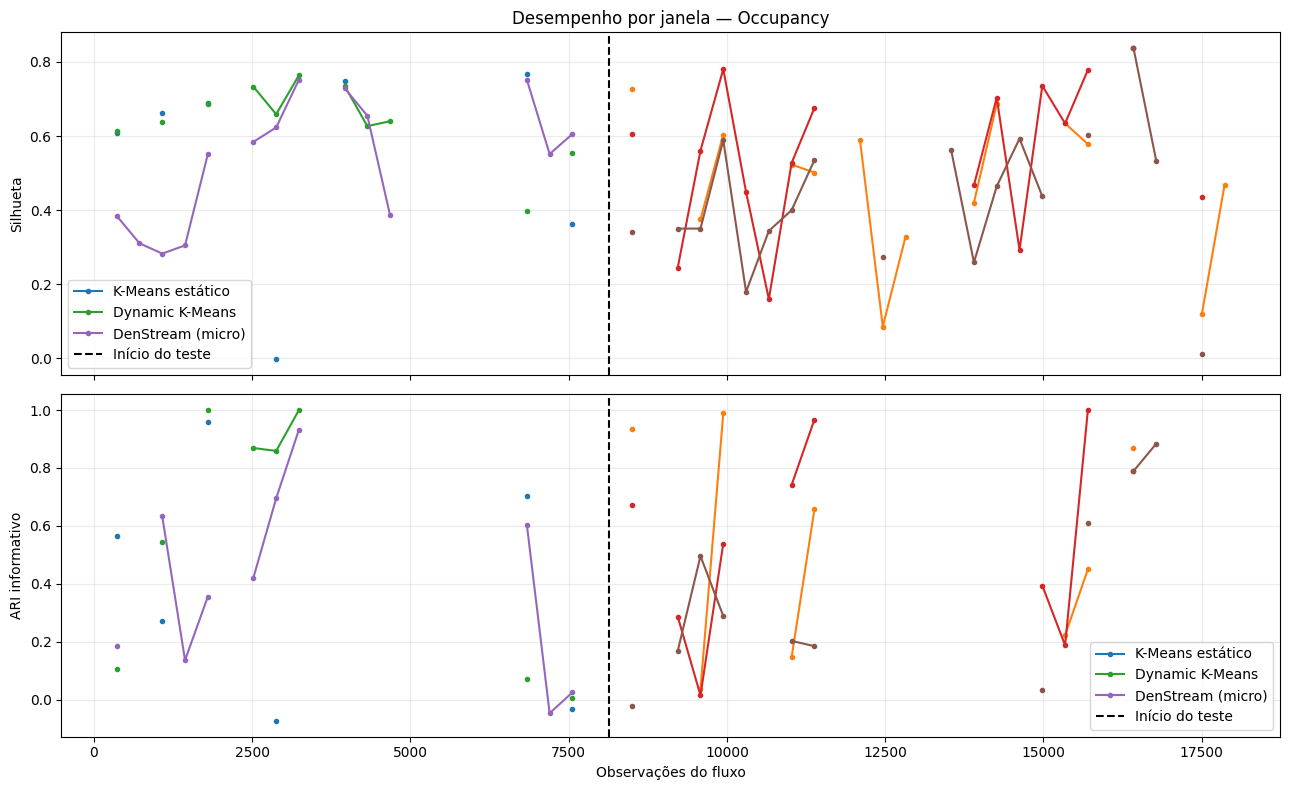

In [43]:
# ============================================================
# 13. GRÁFICOS TEMPORAIS
# ============================================================

fig, axes = plt.subplots(
    2, 1, figsize=(13, 8), sharex=True
)

for nome, d in curvas.items():
    for trecho in ["cal", "teste"]:
        z = d[trecho]

        axes[0].plot(
            z["fim"],
            z["silhueta"],
            marker="o",
            markersize=3,
            label=nome if trecho == "cal" else None
        )

        axes[1].plot(
            z["fim"],
            z["ARI_informativo"],
            marker="o",
            markersize=3,
            label=nome if trecho == "cal" else None
        )

for ax in axes:
    ax.axvline(
        N_CAL,
        linestyle="--",
        color="black",
        label="Início do teste"
    )
    ax.grid(alpha=0.25)
    ax.legend()

axes[0].set_ylabel("Silhueta")
axes[1].set_ylabel("ARI informativo")
axes[1].set_xlabel("Observações do fluxo")

axes[0].set_title(
    "Desempenho por janela — Occupancy"
)

plt.tight_layout()
plt.show()


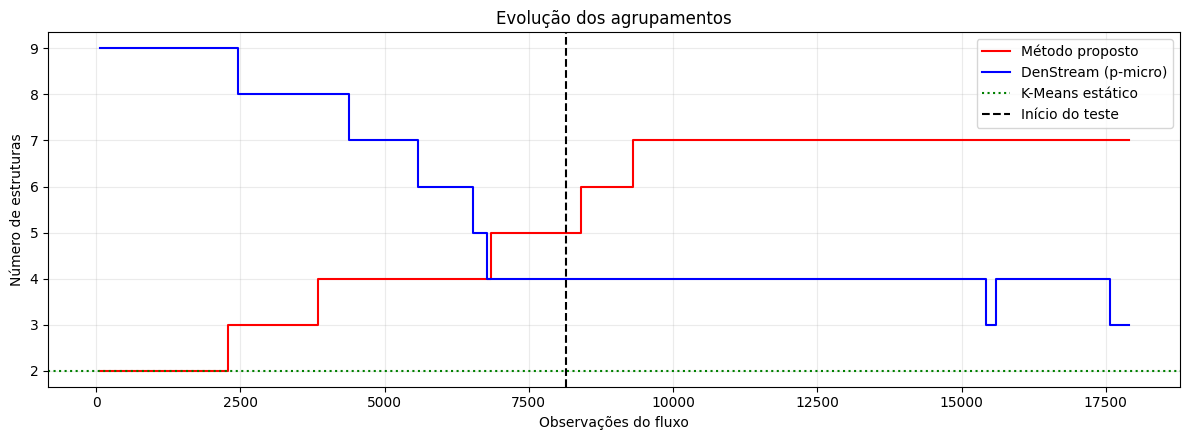

In [44]:
# ============================================================
# 14. EVOLUÇÃO DO NÚMERO DE CLUSTERS
# ============================================================

fig, ax = plt.subplots(figsize=(12, 4.5))

for nome, r, cor, legenda in [
    ("Dynamic K-Means", res_dyn, "red", "Método proposto"),
    ("DenStream (p-micro)", res_den, "blue", "DenStream (p-micro)")
]:
    hist = pd.DataFrame(r["ARI_lotes"])

    # Usa a posição real do final de cada lote.
    fins = np.cumsum([
        len(lote) for lote in lotes_flux
    ])

    ax.step(
        fins,
        hist["Numero_clusters"],
        where="post",
        label=legenda,
        color=cor
    )

ax.axhline(
    K_ESC,
    linestyle=":",
    color="green",
    label="K-Means estático"
)

ax.axvline(
    N_CAL,
    color="black",
    linestyle="--",
    label="Início do teste"
)

ax.set_xlabel("Observações do fluxo")
ax.set_ylabel("Número de estruturas")
ax.set_title("Evolução dos agrupamentos")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()



=== Comparação dos atributos por classe ===
                     Temperature                      Light                        CO2                     Humidity                    
                            mean    std median count   mean    std median count   mean    std median count     mean    std median count
Trecho     Occupancy                                                                                                                   
Calibração 0              -1.069  0.885 -1.200  6414 -0.661  0.358 -0.772  6414 -0.778  0.523 -0.929  6414   -0.002  2.173  0.342  6414
           1               0.233  0.606  0.325  1729  1.066  0.169  1.042  1729  1.093  1.290  0.773  1729    0.736  2.515  0.447  1729
Teste      0              -0.688  0.866 -0.811  7703 -0.673  0.295 -0.772  7703 -0.016  0.987 -0.446  7703    1.936  1.688  2.026  7703
           1               0.584  0.772  0.444  2049  1.195  0.460  1.014  2049  0.636  0.953  0.604  2049    1.587  1.311  1.497  2049


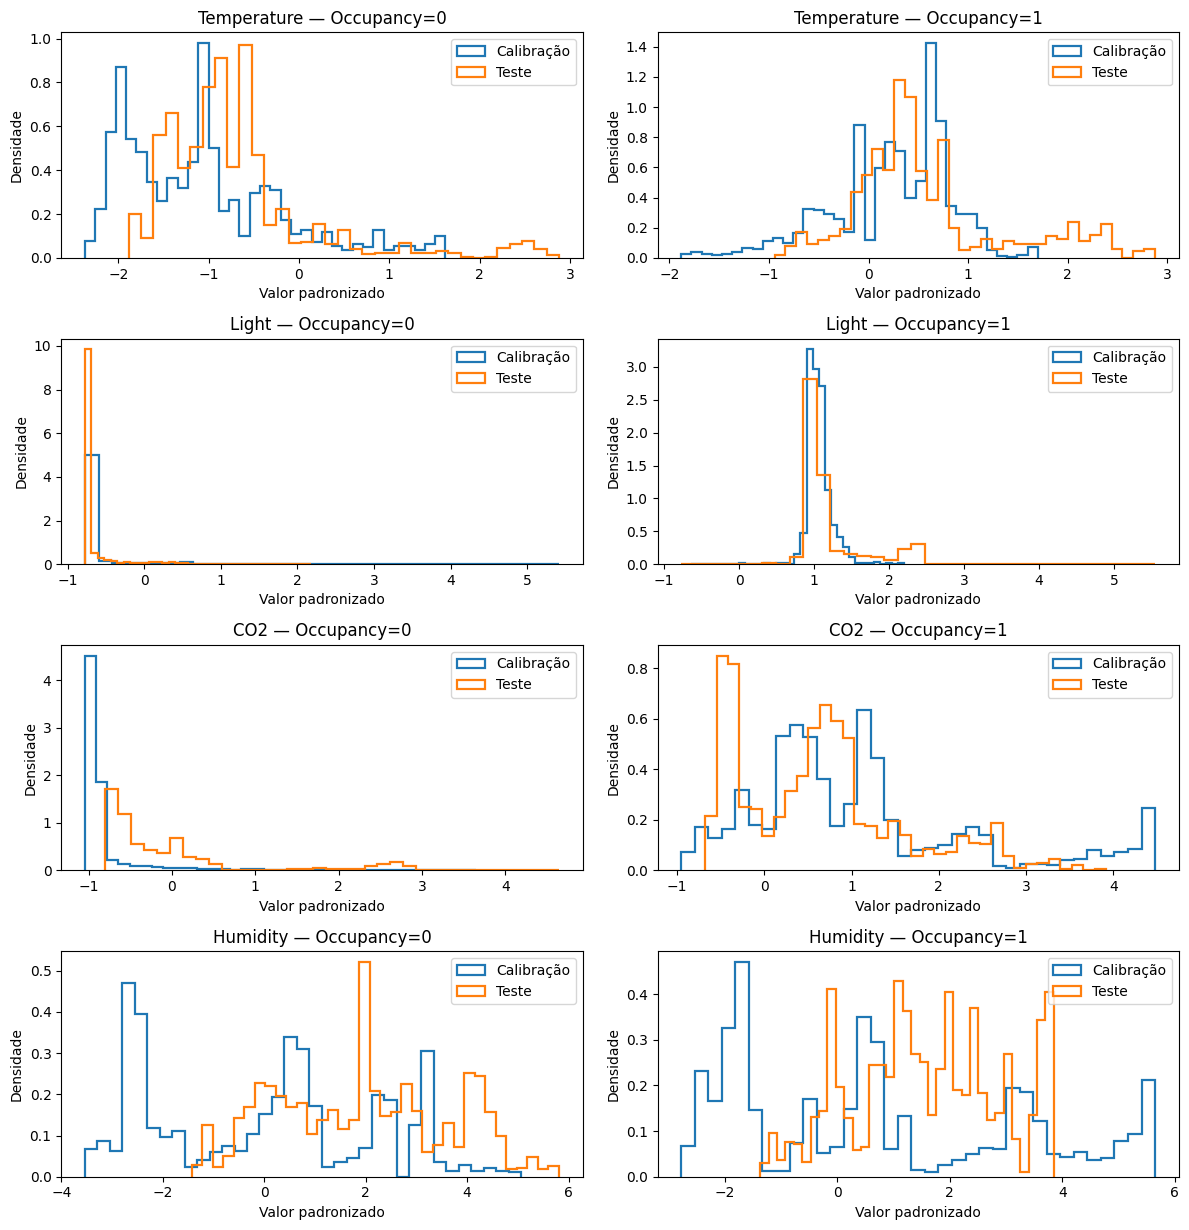

In [45]:
# ============================================================
# 15. DISTRIBUIÇÕES POR CLASSE E PERÍODO
# ============================================================

print("\n=== Comparação dos atributos por classe ===")

base_cal = pd.DataFrame(
    Xcal,
    columns=COLUNAS
)
base_cal["Occupancy"] = ycal
base_cal["Trecho"] = "Calibração"

base_teste = pd.DataFrame(
    Xteste,
    columns=COLUNAS
)
base_teste["Occupancy"] = yteste
base_teste["Trecho"] = "Teste"

dados_atributos = pd.concat(
    [base_cal, base_teste],
    ignore_index=True
)

perfil_classe = dados_atributos.groupby(
    ["Trecho", "Occupancy"]
)[COLUNAS].agg(["mean", "std", "median", "count"])

print(perfil_classe.round(3).to_string())

# Gráficos de distribuição condicional:
# calibração versus teste, dentro de cada classe.
fig, axes = plt.subplots(
    len(COLUNAS), 2,
    figsize=(12, 3.1 * len(COLUNAS))
)

for i, coluna in enumerate(COLUNAS):
    for classe in [0, 1]:

        ax = axes[i, classe]

        for trecho in ["Calibração", "Teste"]:

            z = dados_atributos.loc[
                (dados_atributos["Trecho"] == trecho)
                &
                (dados_atributos["Occupancy"] == classe),
                coluna
            ].dropna()

            # Histograma de densidade para permitir
            # comparação com amostras de tamanhos distintos.
            ax.hist(
                z,
                bins=35,
                density=True,
                histtype="step",
                linewidth=1.6,
                label=trecho
            )

        ax.set_title(
            f"{coluna} — Occupancy={classe}"
        )
        ax.set_xlabel("Valor padronizado")
        ax.set_ylabel("Densidade")
        ax.legend()

plt.tight_layout()
plt.show()


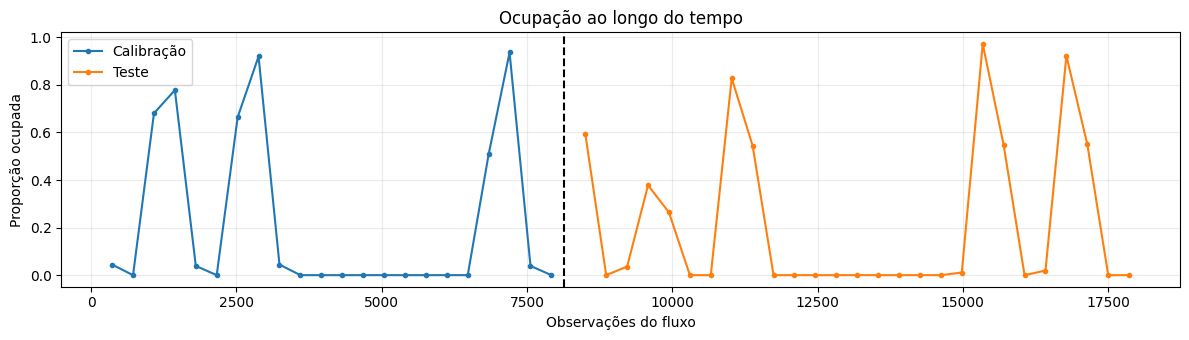

In [46]:
# ============================================================
# 16. COMPOSIÇÃO TEMPORAL DA OCUPAÇÃO
# ============================================================

fig, ax = plt.subplots(figsize=(12, 3.5))

for trecho, z in diag_ocupacao.groupby("trecho"):

    deslocamento = (
        0 if trecho == "Calibração" else N_CAL
    )

    ax.plot(
        z["fim"] + deslocamento,
        z["frac_ocupada"],
        marker=".",
        label=trecho
    )

ax.axvline(
    N_CAL,
    color="black",
    linestyle="--"
)

ax.set_xlabel("Observações do fluxo")
ax.set_ylabel("Proporção ocupada")
ax.set_title("Ocupação ao longo do tempo")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


In [47]:
# ============================================================
# 17. EXPORTAR RESULTADOS
# ============================================================

arquivos = {
    "occupancy_k.csv": tabela_k,
    "occupancy_grade_dynamic.csv": grade_dyn,
    "occupancy_grade_denstream.csv": grade_den,
    "occupancy_resultado_final.csv": tabela_final,
    "occupancy_ablacao.csv": tabela_ablacao,
    "occupancy_janelas_comuns_teste.csv": sil_teste_comuns,
    "occupancy_perfil_por_classe.csv": perfil_classe,
    "occupancy_janelas_ocupacao.csv": diag_ocupacao
}

for nome, tabela in arquivos.items():
    tabela.to_csv(nome)

for nome, tab in tabelas_composicao.items():
    arquivo = (
        "occupancy_clusters_"
        + nome.lower()
            .replace(" ", "_")
            .replace("-", "_")
            .replace("(", "")
            .replace(")", "")
        + ".csv"
    )
    tab.to_csv(arquivo)

print("\nExperimento finalizado.")
print("Resultados salvos em CSV.")



Experimento finalizado.
Resultados salvos em CSV.


## 8. Diagnósticos exploratórios da Occupancy

Estatísticas descritivas e janelas de avaliação; resultados antigos não são carregados nem reutilizados.

In [5]:
# ============================================================
# OCCUPANCY DETECTION
# ANÁLISE EXPLORATÓRIA + DIAGNÓSTICO FINAL
#
# Executar após o experimento anterior.
# Não modifica os algoritmos nem suas predições.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score
)

COLS_EDA = [
    "Temperature", "Light", "CO2",
    "Humidity", "HumidityRatio"
]


In [26]:
# ============================================================
# 1. PREPARAÇÃO
# ============================================================

dados_eda = df.copy()

dados_eda["date"] = pd.to_datetime(
    dados_eda["date"]
)

dados_eda = dados_eda.sort_values(
    "date"
).reset_index(drop=True)

dados_eda["hora"] = dados_eda["date"].dt.hour
dados_eda["dia_semana"] = dados_eda["date"].dt.dayofweek

nomes_dias = [
    "Seg", "Ter", "Qua", "Qui",
    "Sex", "Sáb", "Dom"
]

dados_eda["dia_nome"] = (
    dados_eda["dia_semana"].map(
        dict(enumerate(nomes_dias))
    )
)

# Obter o conjunto de teste com datas.
dados_teste_eda = (
    dados_eda[
        dados_eda["origem"] == ARQ_TESTE
    ].copy().reset_index(drop=True)
)

dados_cal_eda = (
    dados_eda[
        dados_eda["origem"] == ARQ_CAL
    ].copy().reset_index(drop=True)
)

# Verificação de alinhamento com as predições.
assert len(dados_cal_eda) == N_CAL
assert len(dados_teste_eda) == len(yteste)

assert np.array_equal(
    dados_teste_eda["Occupancy"].to_numpy(),
    yteste
)

for nome, pred in predicoes.items():
    assert len(pred) == len(fluxo)

print("Observações:", len(dados_eda))
print("Período inicial:", dados_eda["date"].min())
print("Período final:", dados_eda["date"].max())
print("Valores ausentes:", dados_eda.isna().sum().sum())


Observações: 20560
Período inicial: 2015-02-02 14:19:00
Período final: 2015-02-18 09:19:00
Valores ausentes: 0


In [27]:
# ============================================================
# 2. DESCRIÇÃO GERAL
# ============================================================

print("\n=== Estatísticas descritivas ===")

descricao = dados_eda[COLS_EDA].describe().T

print(
    descricao.round(3).to_string()
)

print("\n=== Ocupação por conjunto ===")

tabela_ocupacao = []

for nome, dados in [
    ("Inicialização", base),
    ("Calibração", cal),
    ("Teste", teste)
]:

    tabela_ocupacao.append({
        "Conjunto": nome,
        "N": len(dados),
        "Desocupada": int(
            (dados["Occupancy"] == 0).sum()
        ),
        "Ocupada": int(
            (dados["Occupancy"] == 1).sum()
        ),
        "Proporção ocupada": (
            dados["Occupancy"].mean()
        )
    })

tabela_ocupacao = pd.DataFrame(
    tabela_ocupacao
)

print(
    tabela_ocupacao.round(4).to_string(
        index=False
    )
)



=== Estatísticas descritivas ===
                 count     mean      std      min      25%      50%      75%       max
Temperature    20560.0   20.906    1.055   19.000   20.200   20.700   21.525    24.408
Light          20560.0  130.757  210.431    0.000    0.000    0.000  301.000  1697.250
CO2            20560.0  690.553  311.201  412.750  460.000  565.417  804.667  2076.500
Humidity       20560.0   27.656    4.982   16.745   24.500   27.290   31.290    39.500
HumidityRatio  20560.0    0.004    0.001    0.003    0.004    0.004    0.005     0.006

=== Ocupação por conjunto ===
     Conjunto    N  Desocupada  Ocupada  Proporção ocupada
Inicialização 2665        1693      972             0.3647
   Calibração 8143        6414     1729             0.2123
        Teste 9752        7703     2049             0.2101


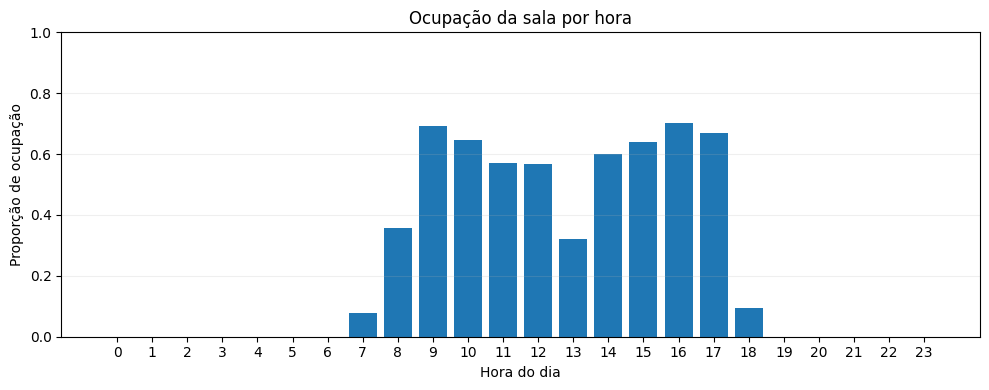

In [28]:
# ============================================================
# 3. OCUPAÇÃO POR HORA
# ============================================================

ocupacao_hora = (
    dados_eda.groupby("hora")["Occupancy"]
    .agg(["mean", "size"])
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 4))

ax.bar(
    ocupacao_hora["hora"],
    ocupacao_hora["mean"]
)

ax.set_xticks(range(24))
ax.set_xlabel("Hora do dia")
ax.set_ylabel("Proporção de ocupação")
ax.set_title("Ocupação da sala por hora")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


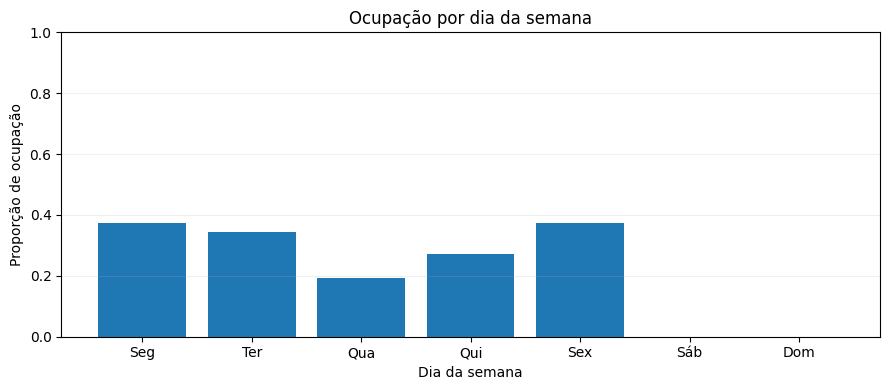

In [29]:
# ============================================================
# 4. OCUPAÇÃO POR DIA DA SEMANA
# ============================================================

ocupacao_dia = (
    dados_eda.groupby("dia_semana")["Occupancy"]
    .agg(["mean", "size"])
    .reindex(range(7))
)

fig, ax = plt.subplots(figsize=(9, 4))

ax.bar(
    nomes_dias,
    ocupacao_dia["mean"]
)

ax.set_xlabel("Dia da semana")
ax.set_ylabel("Proporção de ocupação")
ax.set_title("Ocupação por dia da semana")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


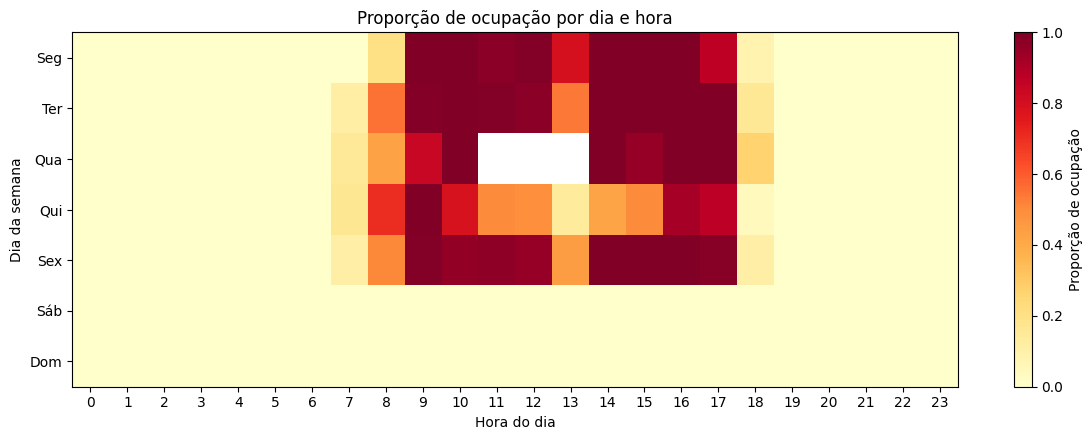

In [30]:
# ============================================================
# 5. MAPA DE CALOR — DIA X HORA
# ============================================================

matriz_ocupacao = dados_eda.pivot_table(
    index="dia_semana",
    columns="hora",
    values="Occupancy",
    aggfunc="mean"
).reindex(
    index=range(7),
    columns=range(24)
)

fig, ax = plt.subplots(figsize=(12, 4.5))

im = ax.imshow(
    matriz_ocupacao.to_numpy(),
    aspect="auto",
    vmin=0,
    vmax=1,
    cmap="YlOrRd"
)

ax.set_yticks(range(7))
ax.set_yticklabels(nomes_dias)
ax.set_xticks(range(24))
ax.set_xlabel("Hora do dia")
ax.set_ylabel("Dia da semana")
ax.set_title("Proporção de ocupação por dia e hora")

plt.colorbar(
    im,
    ax=ax,
    label="Proporção de ocupação"
)

plt.tight_layout()
plt.show()


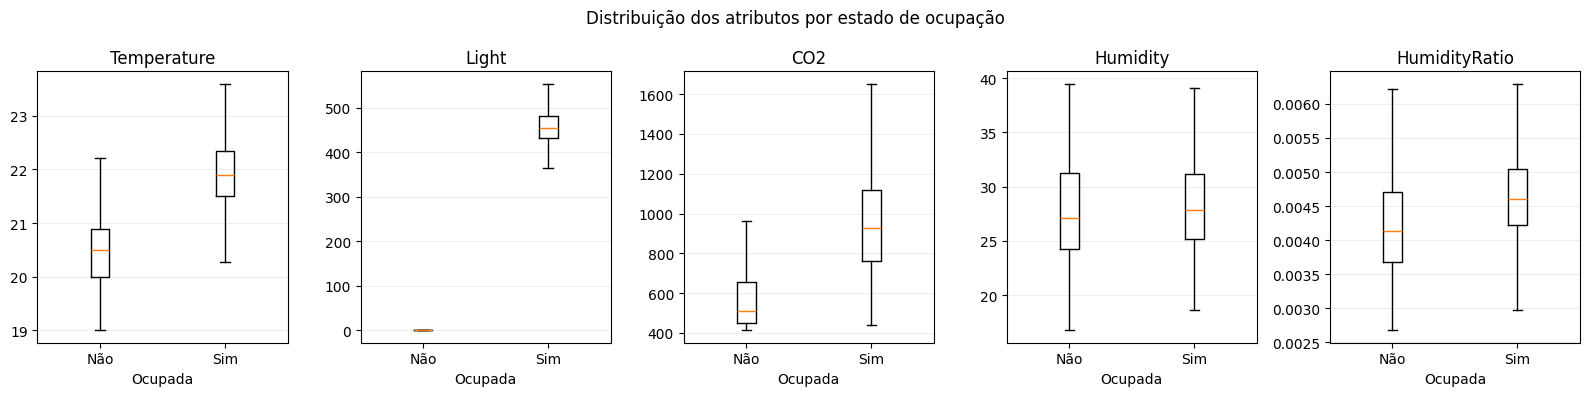

In [31]:
# ============================================================
# 6. DISTRIBUIÇÃO DAS VARIÁVEIS POR OCUPAÇÃO
# ============================================================

fig, axes = plt.subplots(
    1, len(COLS_EDA),
    figsize=(16, 4)
)

for ax, coluna in zip(axes, COLS_EDA):

    valores = [
        dados_eda.loc[
            dados_eda["Occupancy"] == classe,
            coluna
        ].to_numpy()
        for classe in [0, 1]
    ]

    ax.boxplot(
        valores,
        tick_labels=["Não", "Sim"],
        showfliers=False
    )

    ax.set_title(coluna)
    ax.set_xlabel("Ocupada")
    ax.grid(axis="y", alpha=0.2)

plt.suptitle(
    "Distribuição dos atributos por estado de ocupação"
)
plt.tight_layout()
plt.show()


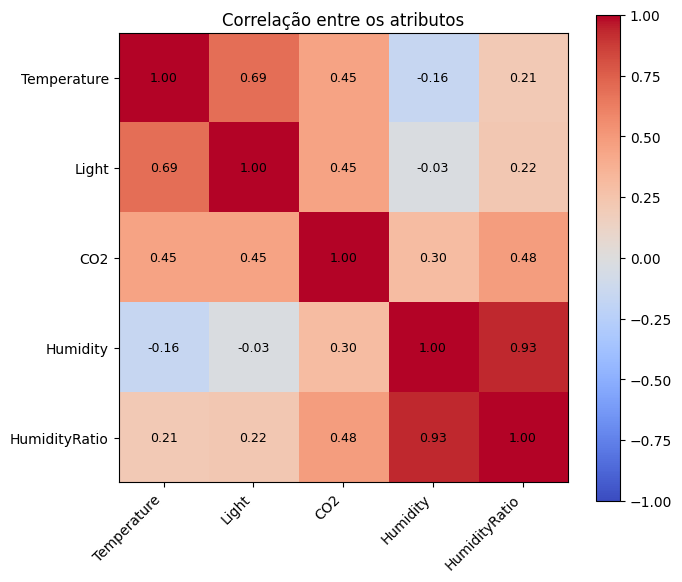

In [32]:
# ============================================================
# 7. CORRELAÇÃO ENTRE OS ATRIBUTOS
# ============================================================

corr = dados_eda[COLS_EDA].corr()

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    corr,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

ax.set_xticks(range(len(COLS_EDA)))
ax.set_yticks(range(len(COLS_EDA)))

ax.set_xticklabels(
    COLS_EDA,
    rotation=45,
    ha="right"
)
ax.set_yticklabels(COLS_EDA)

for i in range(len(COLS_EDA)):
    for j in range(len(COLS_EDA)):
        ax.text(
            j, i,
            f"{corr.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

plt.colorbar(im, ax=ax)
ax.set_title("Correlação entre os atributos")

plt.tight_layout()
plt.show()


Observações utilizadas: 2665

Matriz de correlação:
               Temperature   Light     CO2  Humidity  HumidityRatio
Temperature         1.0000  0.7684  0.8702    0.7170         0.8945
Light               0.7684  1.0000  0.7692    0.5619         0.6933
CO2                 0.8702  0.7692  1.0000    0.9116         0.9644
Humidity            0.7170  0.5619  0.9116    1.0000         0.9519
HumidityRatio       0.8945  0.6933  0.9644    0.9519         1.0000

Correlação entre Humidity e HumidityRatio: 0.9519


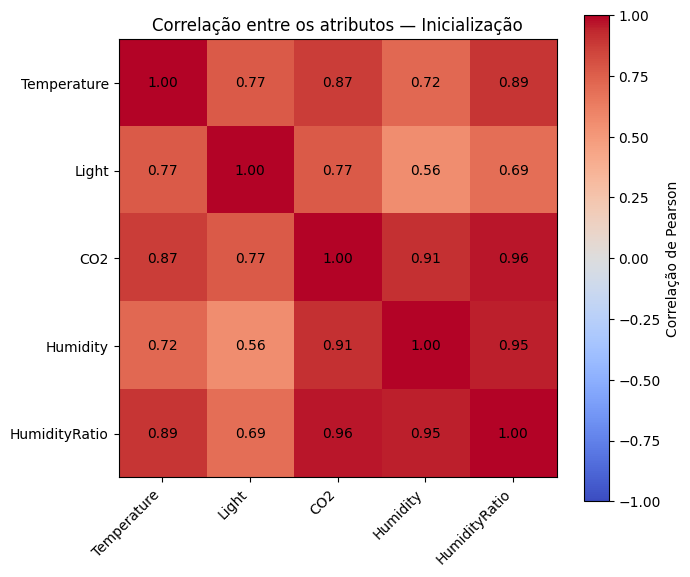

In [33]:

# ============================================================
# 7. CORRELAÇÃO ENTRE OS ATRIBUTOS — APENAS INICIALIZAÇÃO
# ============================================================

COLS_EDA = [
    "Temperature", "Light", "CO2",
    "Humidity", "HumidityRatio"
]

# Utilizar somente as observações iniciais (X0)
dados_corr = base[COLS_EDA].copy()

# Matriz de correlação de Pearson
corr = dados_corr.corr(method="pearson")

print(f"Observações utilizadas: {len(dados_corr)}")
print("\nMatriz de correlação:")
print(corr.round(4))

print(
    "\nCorrelação entre Humidity e HumidityRatio:",
    round(corr.loc["Humidity", "HumidityRatio"], 4)
)

# Gráfico
fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    corr,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

ax.set_xticks(range(len(COLS_EDA)))
ax.set_yticks(range(len(COLS_EDA)))

ax.set_xticklabels(
    COLS_EDA,
    rotation=45,
    ha="right"
)
ax.set_yticklabels(COLS_EDA)

for i in range(len(COLS_EDA)):
    for j in range(len(COLS_EDA)):
        ax.text(
            j, i,
            f"{corr.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=10
        )

plt.colorbar(im, ax=ax, label="Correlação de Pearson")

ax.set_title(
    "Correlação entre os atributos — Inicialização"
)

plt.tight_layout()

plt.savefig(
    "correlacao_inicializacao.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [56]:
# ============================================================
# 8. DEFINIR JANELAS TEMPORAIS DO TESTE
# ============================================================

# Usar as mesmas janelas do experimento anterior.
# Nenhuma janela atravessa a divisão cal/teste.

janelas_teste = [
    (i, i + JANELA)
    for i in range(
        0,
        len(yteste) - JANELA + 1,
        PASSO
    )
]

# Aqui queremos identificar:
# - se o período contém ocupação
# - quantas classes reais aparecem
# - quantos clusters cada algoritmo identifica
# - se a silhueta é definida

diagnosticos = []

for numero, (ini, fim) in enumerate(
    janelas_teste, start=1
):

    yj = yteste[ini:fim]
    Xj = Xteste[ini:fim]

    proporcao_ocupada = float(
        np.mean(yj == 1)
    )

    n_classes = len(np.unique(yj))

    inicio_data = (
        dados_teste_eda["date"].iloc[ini]
    )
    fim_data = (
        dados_teste_eda["date"].iloc[fim - 1]
    )

    for nome, pred in predicoes.items():

        pj = np.asarray(
            pred[N_CAL + ini:N_CAL + fim]
        )

        n_clusters = len(np.unique(pj))

        sil = np.nan
        if 2 <= n_clusters < len(pj):
            sil = silhouette_score(Xj, pj)

        ari = np.nan
        if n_classes >= 2 and n_clusters >= 2:
            ari = adjusted_rand_score(yj, pj)

        diagnosticos.append({
            "Janela": numero,
            "Método": nome,
            "Início": inicio_data,
            "Fim": fim_data,
            "N": len(yj),
            "Prop_ocupada": proporcao_ocupada,
            "Classes_reais": n_classes,
            "Clusters": n_clusters,
            "Silhueta": sil,
            "ARI_informativo": ari,
            "Um_cluster": n_clusters == 1,
            "Silhueta_valida": np.isfinite(sil),
            "Somente_desocupada": (
                np.all(yj == 0)
            ),
            "Somente_ocupada": (
                np.all(yj == 1)
            ),
            "Duas_classes": n_classes == 2
        })

diagnostico = pd.DataFrame(
    diagnosticos
)


In [57]:
# ============================================================
# 9. TABELA PRINCIPAL: UM CLUSTER X OCUPAÇÃO
# ============================================================

print(
    "\n=== Relação entre um cluster e ocupação ==="
)

for nome, d in diagnostico.groupby("Método"):

    print(f"\n{nome}")

    tabela = pd.crosstab(
        d["Um_cluster"],
        d["Somente_desocupada"],
        rownames=["Um único cluster"],
        colnames=["Somente desocupada"]
    )

    print(tabela)

    apenas_um = d[d["Um_cluster"]]

    if len(apenas_um) > 0:

        frac = (
            apenas_um["Somente_desocupada"].mean()
        )

        print(
            "Entre janelas com um único cluster, "
            "fração totalmente desocupada:",
            round(frac, 4)
        )

        print(
            "Ocupação média nessas janelas:",
            round(
                apenas_um["Prop_ocupada"].mean(),
                4
            )
        )

    else:
        print(
            "O método não produziu janelas "
            "com um único cluster."
        )



=== Relação entre um cluster e ocupação ===

DenStream (micro)
Somente desocupada  False  True 
Um único cluster                
False                  10      8
True                    2      7
Entre janelas com um único cluster, fração totalmente desocupada: 0.7778
Ocupação média nessas janelas: 0.1691

Dynamic K-Means
Somente desocupada  False  True 
Um único cluster                
False                  10      6
True                    2      9
Entre janelas com um único cluster, fração totalmente desocupada: 0.8182
Ocupação média nessas janelas: 0.1338

K-Means estático
Somente desocupada  False  True 
Um único cluster                
False                   8      7
True                    4      8
Entre janelas com um único cluster, fração totalmente desocupada: 0.6667
Ocupação média nessas janelas: 0.1266


In [58]:
# ============================================================
# 10. RESUMO DOS DIAGNÓSTICOS
# ============================================================

resumo_diagnostico = (
    diagnostico.groupby("Método")
    .agg(
        Janelas=("Janela", "size"),
        Janelas_um_cluster=("Um_cluster", "sum"),
        Frac_um_cluster=("Um_cluster", "mean"),
        Frac_sil_valida=("Silhueta_valida", "mean"),
        Ocupacao_media=("Prop_ocupada", "mean"),
        Frac_ARI_informativo=(
            "ARI_informativo",
            lambda x: x.notna().mean()
        )
    )
)

print("\n=== Resumo dos diagnósticos ===")

print(
    resumo_diagnostico.round(4).to_string()
)



=== Resumo dos diagnósticos ===
                   Janelas  Janelas_um_cluster  Frac_um_cluster  Frac_sil_valida  Ocupacao_media  Frac_ARI_informativo
Método                                                                                                                
DenStream (micro)       27                   9           0.3333           0.6667          0.2099                0.3704
Dynamic K-Means         27                  11           0.4074           0.5926          0.2099                0.3704
K-Means estático        27                  12           0.4444           0.5556          0.2099                0.2963


In [59]:
# ============================================================
# 11. TABELA DETALHADA POR JANELA
# ============================================================

# Uma linha por período, com o estado real
# e a quantidade de clusters de cada método.

tabela_janelas = diagnostico.pivot(
    index="Janela",
    columns="Método",
    values="Clusters"
)

informacoes = (
    diagnostico
    .drop_duplicates("Janela")
    .set_index("Janela")[
        [
            "Início",
            "Fim",
            "Prop_ocupada",
            "Classes_reais"
        ]
    ]
)

tabela_janelas = informacoes.join(
    tabela_janelas
)

print("\n=== Diagnóstico por janela ===")

print(
    tabela_janelas.round(3).to_string()
)



=== Diagnóstico por janela ===
                    Início                 Fim  Prop_ocupada  Classes_reais  DenStream (micro)  Dynamic K-Means  K-Means estático
Janela                                                                                                                           
1      2015-02-11 14:48:00 2015-02-11 20:47:00         0.594              2                  2                3                 2
2      2015-02-11 20:48:00 2015-02-12 02:47:00         0.000              1                  1                1                 1
3      2015-02-12 02:48:00 2015-02-12 08:47:00         0.036              2                  3                3                 1
4      2015-02-12 08:48:00 2015-02-12 14:47:00         0.378              2                  3                2                 2
5      2015-02-12 14:48:00 2015-02-12 20:47:00         0.264              2                  2                3                 2
6      2015-02-12 20:48:00 2015-02-13 02:47:00         0.0

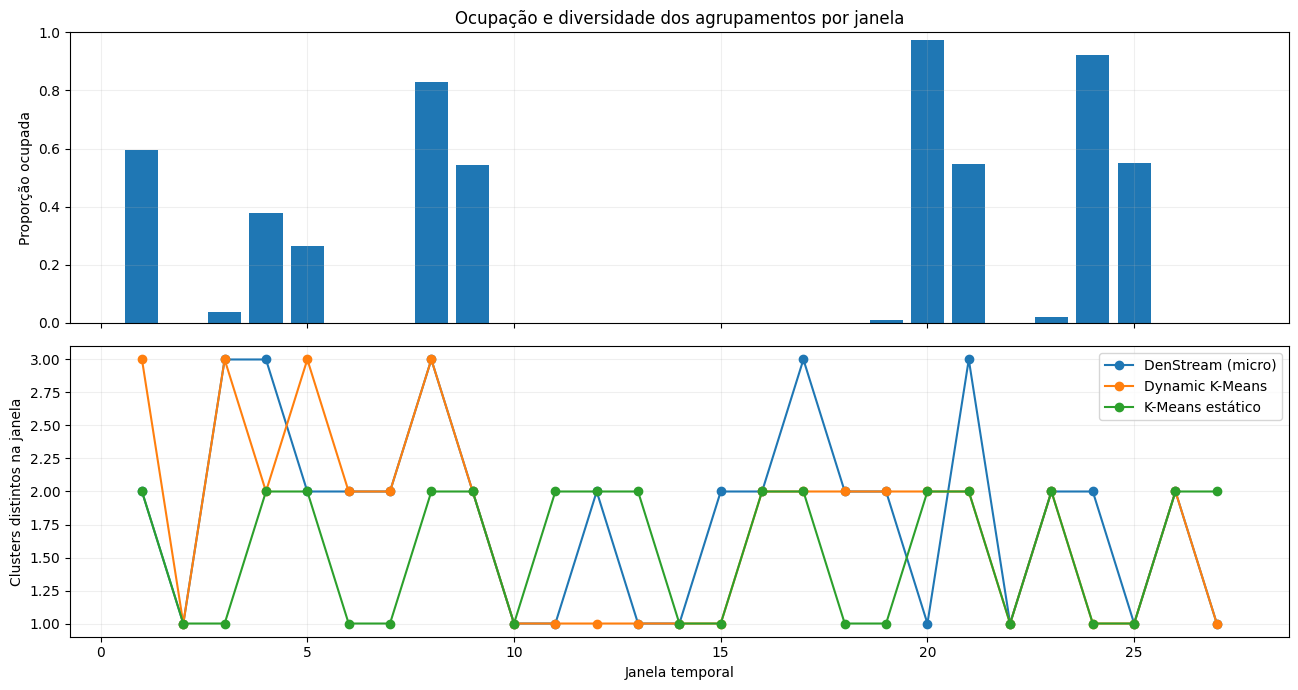

In [60]:
# ============================================================
# 12. GRÁFICO: OCUPAÇÃO X NÚMERO DE CLUSTERS
# ============================================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 7),
    sharex=True
)

real = (
    diagnostico
    .drop_duplicates("Janela")
    .sort_values("Janela")
)

axes[0].bar(
    real["Janela"],
    real["Prop_ocupada"],
    width=0.8
)

axes[0].set_ylabel("Proporção ocupada")
axes[0].set_ylim(0, 1)
axes[0].set_title(
    "Ocupação e diversidade dos agrupamentos por janela"
)

for nome, d in diagnostico.groupby("Método"):

    d = d.sort_values("Janela")

    axes[1].plot(
        d["Janela"],
        d["Clusters"],
        marker="o",
        label=nome
    )

axes[1].set_ylabel(
    "Clusters distintos na janela"
)
axes[1].set_xlabel("Janela temporal")
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


In [61]:
# ============================================================
# 13. RESUMO CRUZADO:
# TIPO DE JANELA X QUANTIDADE DE CLUSTERS
# ============================================================

def classificar_janela(linha):

    if linha["Somente_desocupada"]:
        return "Somente desocupada"

    if linha["Somente_ocupada"]:
        return "Somente ocupada"

    return "Mista"


diagnostico["Tipo_janela"] = diagnostico.apply(
    classificar_janela,
    axis=1
)

print("\n=== Tipo de janela x clusters ===")

for nome, d in diagnostico.groupby("Método"):

    print(f"\n{nome}")

    tab = pd.crosstab(
        d["Tipo_janela"],
        d["Clusters"]
    )

    print(tab.to_string())



=== Tipo de janela x clusters ===

DenStream (micro)
Clusters            1  2  3
Tipo_janela                
Mista               2  6  4
Somente desocupada  7  7  1

Dynamic K-Means
Clusters            1  2  3
Tipo_janela                
Mista               2  6  4
Somente desocupada  9  6  0

K-Means estático
Clusters            1  2
Tipo_janela             
Mista               4  8
Somente desocupada  8  7


In [62]:
# ============================================================
# 14. EXPORTAÇÃO
# ============================================================

descricao.to_csv(
    "occupancy_descritivas.csv"
)

tabela_ocupacao.to_csv(
    "occupancy_proporcao_classes.csv",
    index=False
)

ocupacao_hora.to_csv(
    "occupancy_por_hora.csv",
    index=False
)

ocupacao_dia.to_csv(
    "occupancy_por_dia.csv"
)

corr.to_csv(
    "occupancy_correlacoes.csv"
)

diagnostico.to_csv(
    "occupancy_diagnostico_janelas.csv",
    index=False
)

resumo_diagnostico.to_csv(
    "occupancy_resumo_diagnostico.csv"
)

tabela_janelas.to_csv(
    "occupancy_clusters_por_janela.csv"
)

print("\nAnálise exploratória e diagnóstico concluídos.")



Análise exploratória e diagnóstico concluídos.


In [63]:
# Verificação final — Dynamic K-Means

historico = pd.DataFrame(res_dyn["ARI_lotes"])

contagens = historico["Numero_clusters"].to_numpy()

print("Clusters iniciais:", K_ESC)
print("Clusters finais:", res_dyn["Numero_clusters_final"])

print(
    "Histórico não decrescente:",
    bool(np.all(np.diff(contagens) >= 0))
)

print(
    "Clusters adicionais:",
    res_dyn["Numero_clusters_final"] - K_ESC
)

print(
    "IDs encontrados no teste:",
    np.unique(pred_dyn[N_CAL:])
)

print(
    "IDs que não receberam observações no teste:",
    sorted(
        set(range(res_dyn["Numero_clusters_final"]))
        - set(np.unique(pred_dyn[N_CAL:]))
    )
)

assert np.all(np.diff(contagens) >= 0)
assert contagens[-1] == res_dyn["Numero_clusters_final"]
assert len(pred_dyn) == len(fluxo)
assert len(np.unique(pred_dyn[N_CAL:])) == 6


Clusters iniciais: 2
Clusters finais: 7
Histórico não decrescente: True
Clusters adicionais: 5
IDs encontrados no teste: [0 1 2 4 5 6]
IDs que não receberam observações no teste: [3]


## 9. Verificação offline na Occupancy

Rotina complementar usando o modelo final selecionado na calibração.

Esta etapa não substitui os resultados com p-micro-clusters. Usa a implementação nativa predict_one do River, que agrupa os p-micro-clusters por conectividade de densidade antes de atribuir cada ponto ao macro-centro mais próximo.

Protocolo: parâmetros congelados após a calibração; inicialização em X0; avaliação do lote com o modelo anterior à atualização; atualização com os pontos do lote; alinhamento de IDs de macro-clusters entre lotes. A comparação com o Dynamic K-Means ainda apresenta diferenças no instante da atribuição (pré-lote versus atualizações dentro do lote).

Sobre os IDs: o alinhamento usa a correspondência húngara entre centros de macro-clusters, com limite de distância 2*epsilon. Essa associação é um recurso para obter IDs persistentes nas métricas globais, e não faz parte da regra nativa do River. Ela pode afetar o ARI global; por isso também são reportadas métricas por janela.

In [64]:
from river import cluster as river_cluster
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment


def avaliar_denstream_offline(df_base, lotes, config):
    """River offline nativo; pré-lote; IDs persistentes via casamento de centros."""
    X0_df = obter_variaveis(df_base)
    colunas = list(X0_df.columns)
    modelo = river_cluster.DenStream(**config)
    for x in X0_df.to_dict(orient="records"):
        modelo.learn_one(x)

    ids_prev = np.array([], dtype=int)
    centros_prev = np.empty((0, len(colunas)))
    proximo_id = 0
    predicoes = []
    historico = []
    y_true = []

    for indice_lote, lote in enumerate(lotes, 1):
        xl_df = obter_variaveis(lote)
        X = xl_df.to_numpy(float)
        registros = xl_df.to_dict(orient="records")
        y = lote["Grupo"].to_numpy()

        # Chamada nativa dispara a fase offline do River para o estado ATUAL.
        # Os rótulos nativos são reatribuídos a cada novo reclustering.
        modelo.predict_one(registros[0])
        centros_dict = modelo.centers  # macro-centros calculados pelo River
        chaves = list(centros_dict)
        centros = np.array([
            [centros_dict[k].get(c, 0.0) for c in colunas]
            for k in chaves
        ], dtype=float).reshape(-1, len(colunas))
        n_macros_antes = len(centros)

        if n_macros_antes == 0:
            pred = np.full(len(X), -1, dtype=int)
        else:
            # Alinhamento de macro-IDs entre lotes para evitar renumeração arbitrária.
            ids = np.full(n_macros_antes, -1, dtype=int)
            if len(centros_prev):
                dist = cdist(centros, centros_prev)
                rr, cc = linear_sum_assignment(dist)
                for r, c in zip(rr, cc):
                    if dist[r, c] <= 2.0 * config["epsilon"]:
                        ids[r] = ids_prev[c]
            for i in range(len(ids)):
                if ids[i] < 0:
                    ids[i] = proximo_id
                    proximo_id += 1
            pred = ids[cdist(X, centros).argmin(axis=1)]
            centros_prev, ids_prev = centros.copy(), ids.copy()

        predicoes.extend(pred)
        y_true.extend(y)
        for registro in registros:
            modelo.learn_one(registro)
        historico.append({
            "Lote": indice_lote,
            "Numero_macro_antes": n_macros_antes,
            "Numero_micro_depois": len(modelo.p_micro_clusters),
        })

    # Macro-clusters após TODO o fluxo, sem contaminar predições passadas.
    if len(predicoes):
        # Usar um registro conhecido somente para solicitar reclustering, sem aprendizado.
        modelo.predict_one(registros[-1])
        n_macro_final = modelo.n_clusters
    else:
        n_macro_final = 0
    return {
        "y_true_stream": np.array(y_true),
        "y_pred_stream": np.array(predicoes),
        "Numero_macro_final": n_macro_final,
        "historico": pd.DataFrame(historico),
        "observacao": "ARI global condicionado ao alinhamento de IDs por centros"
    }

res_offline = avaliar_denstream_offline(df_base, lotes_flux, cfg_den)
pred_offline = res_offline["y_pred_stream"]
assert len(pred_offline) == len(Xflux)

# Reaproveitar exatamente as funções de avaliação já definidas.
met = resumir_janelas(Xteste, yteste, pred_offline[N_CAL:])
resumo_offline = pd.DataFrame([
    {
        "Método": "DenStream (micro)",
        "Silhueta teste": tabela_final.set_index("Método").loc["DenStream (micro)", "Sil_teste"],
        "Janelas válidas": tabela_final.set_index("Método").loc["DenStream (micro)", "Validas_teste"],
        "ARI teste": tabela_final.set_index("Método").loc["DenStream (micro)", "ARI_teste"],
        "Estruturas finais": res_den["Numero_clusters_final"]
    },
    {
        "Método": "DenStream (macro/offline)",
        "Silhueta teste": met["silhueta"],
        "Janelas válidas": met["frac_sil_valida"],
        "ARI teste": adjusted_rand_score(yteste, pred_offline[N_CAL:]),
        "Estruturas finais": res_offline["Numero_macro_final"]
    }
])
print(resumo_offline.round(4).to_string(index=False))
print("IDs macro distintos no teste:", np.unique(pred_offline[N_CAL:]))
print("Macros por lote (resumo):")
print(res_offline["historico"].describe().round(2))
resumo_offline.to_csv("occupancy_denstream_offline.csv", index=False)

# Silhueta pareada (somente janelas válidas em ambas as variantes).
micro_w = metricas_janelas(Xteste, yteste, pred_den[N_CAL:])
macro_w = metricas_janelas(Xteste, yteste, pred_offline[N_CAL:])
w = pd.DataFrame({"micro": micro_w["silhueta"], "macro": macro_w["silhueta"]}).dropna()
print("Janelas comuns micro/macro:", len(w), "de", len(micro_w))
if len(w):
    print("Silhueta média pareada:", w.mean().round(4).to_dict())
    print("Diferença macro - micro:", round(float((w["macro"] - w["micro"]).mean()), 4))


                   Método  Silhueta teste  Janelas válidas  ARI teste  Estruturas finais
        DenStream (micro)          0.4258           0.6667     0.0820                  3
DenStream (macro/offline)          0.4369           0.6667     0.0815                  3
IDs macro distintos no teste: [ 6  7  8  9 10 11 12 13 14 15]
Macros por lote (resumo):
         Lote  Numero_macro_antes  Numero_micro_depois
count  299.00              299.00               299.00
mean   150.00                5.40                 5.38
std     86.46                2.01                 2.00
min      1.00                3.00                 3.00
25%     75.50                4.00                 4.00
50%    150.00                4.00                 4.00
75%    224.50                7.00                 7.00
max    299.00                9.00                 9.00
Janelas comuns micro/macro: 18 de 27
Silhueta média pareada: {'micro': 0.4258, 'macro': 0.4369}
Diferença macro - micro: 0.0111


In [65]:
# ============================================================
# DENSTREAM — COMPARAÇÃO FINAL ONLINE VS OFFLINE
# Base completa: inicialização + calibração + teste
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score

# 1. Mesmos hiperparâmetros da configuração final
cfg_offline_final = config_den(
    esc_den["epsilon"],
    esc_den["mu"],
    esc_den["meia_vida"]
)
cfg_offline_final["beta"] = float(
    esc_den["beta"] if "beta" in esc_den.index else 0.75
)

print("=== CONFIGURAÇÃO UTILIZADA ===")
print(cfg_offline_final)

# 2. Executar o DenStream offline
# A função reinicializa o modelo em df_base
# e processa todos os lotes de lotes_flux.
res_offline_final = avaliar_denstream_offline(
    df_base,
    lotes_flux,
    cfg_offline_final
)

# 3. Recuperar as predições online e offline
pred_online = np.asarray(
    predicoes["DenStream (micro)"]
)

pred_offline = np.asarray(
    res_offline_final["y_pred_stream"]
)

assert len(pred_online) == len(pred_offline)
assert len(pred_online) == N_CAL + len(yteste)

# 4. Avaliar separadamente calibração e teste
comparacao = []

for etapa, inicio, fim, X, y in [
    ("Calibração", 0, N_CAL, Xcal, ycal),
    ("Teste", N_CAL, len(pred_online), Xteste, yteste)
]:
    micro = pred_online[inicio:fim]
    macro = pred_offline[inicio:fim]

    for nome, pred in [
        ("Online (micro)", micro),
        ("Offline (macro)", macro)
    ]:
        m = resumir_janelas(X, y, pred)

        comparacao.append({
            "Conjunto": etapa,
            "Fase": nome,
            "ARI": adjusted_rand_score(y, pred),
            "Silhueta": m["silhueta"],
            "Janelas_validas": m["frac_sil_valida"],
            "Clusters_distintos": len(np.unique(pred))
        })

tabela_online_offline = pd.DataFrame(comparacao)

print("\n=== COMPARAÇÃO ONLINE VS OFFLINE ===")
print(
    tabela_online_offline.round(4).to_string(index=False)
)

# 5. Comparar as partições diretamente,
# independentemente dos números dos clusters.
print("\n=== CONCORDÂNCIA ENTRE AS DUAS FASES ===")

for etapa, inicio, fim in [
    ("Calibração", 0, N_CAL),
    ("Teste", N_CAL, len(pred_online))
]:
    ari_entre_fases = adjusted_rand_score(
        pred_online[inicio:fim],
        pred_offline[inicio:fim]
    )

    print(
        f"{etapa}: ARI online vs offline = "
        f"{ari_entre_fases:.4f}"
    )

# 6. Quantidade de estruturas ao fim do fluxo
print("\n=== AGRUPAMENTOS FINAIS ===")
print(
    "Micro-clusters potenciais:",
    res_den["Numero_clusters_final"]
)
print(
    "Macroclusters offline:",
    res_offline_final["Numero_macro_final"]
)

# 7. Matrizes de confusão no teste
for nome, pred in [
    ("Online", pred_online[N_CAL:]),
    ("Offline", pred_offline[N_CAL:])
]:
    print(f"\n=== MATRIZ DE CONFUSÃO — {nome} ===")

    matriz = pd.crosstab(
        pd.Series(np.asarray(yteste), name="Ocupação real"),
        pd.Series(pred, name="Cluster estimado")
    )

    print(matriz.to_string())

# 8. Salvar os resultados
tabela_online_offline.to_csv(
    "denstream_online_offline_final.csv",
    index=False
)


=== CONFIGURAÇÃO UTILIZADA ===
{'epsilon': 0.75, 'beta': 0.75, 'mu': 5, 'decaying_factor': 0.08333333333333333, 'n_samples_init': 1000, 'stream_speed': 60}

=== COMPARAÇÃO ONLINE VS OFFLINE ===
  Conjunto            Fase    ARI  Silhueta  Janelas_validas  Clusters_distintos
Calibração  Online (micro) 0.2668    0.5339           0.6364                  10
Calibração Offline (macro) 0.2668    0.5339           0.6364                  10
     Teste  Online (micro) 0.0820    0.4258           0.6667                  11
     Teste Offline (macro) 0.0815    0.4369           0.6667                  10

=== CONCORDÂNCIA ENTRE AS DUAS FASES ===
Calibração: ARI online vs offline = 1.0000
Teste: ARI online vs offline = 0.9969

=== AGRUPAMENTOS FINAIS ===
Micro-clusters potenciais: 3
Macroclusters offline: 3

=== MATRIZ DE CONFUSÃO — Online ===
Cluster estimado    6   7    8   9   10   11    12   13   14    15   16
Ocupação real                                                          
0             

---
## Registro da limpeza

Removidos da versão principal: blocos anteriores sem `tempo`, versões alternativas de `DynamicKMeans`, testes com parâmetros antigos, duplicações de gráficos e matrizes, experimentos com *default* não usados, células vazias, anotações provisórias e a exploração separada de Electricity. Nenhum resultado numérico antigo deve ser interpretado como válido para os novos dados padronizados. O notebook original permanece intacto.